# Clasificación desbalanceada 
**Alondra E. Matos Mendoza**

## 1. Introducción y descripción del problema

Predecir fallas industriales en las próximas 24 horas con un escenario sintético de sensores. Se comparan cinco configuraciones de Regresión logística: sin balanceo, ROS, RUS, SMOTE y ponderación. MCC en CV externa es el criterio principal; kappa de Cohen complementa la evaluación.


### Entorno


In [1]:
# Librerías
import importlib.metadata as metadata
import inspect
import hashlib
import json
import platform
from copy import deepcopy
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from scipy.stats import norm
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss,
    cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, log_loss, matthews_corrcoef, precision_recall_curve,
    precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline
from imblearn.utils import check_sampling_strategy

SEED = 42
paquetes = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'imbalanced-learn',
            'matplotlib', 'nbformat', 'nbclient', 'ipykernel']
versiones = {p: metadata.version(p) for p in paquetes}
print('Python:', platform.python_version())
display(pd.Series(versiones, name='Versión').to_frame())
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.dpi': 115, 'savefig.dpi': 180, 'font.size': 10,
    'axes.titlesize': 12, 'axes.labelsize': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
})
COLORES = {'LR': '#32658a', 'NONE': '#52697a',
           'SIGMOID': '#087f8c', 'ISOTONIC': '#b45b78'}
pd.set_option('display.max_columns', 24)
pd.set_option('display.width', 160)

def tabla(datos, decimales=4):
    """Formato HTML sin modificar los valores usados en los cálculos."""
    formatos = {c: lambda v: str(int(v)) for c in datos.columns if c == 'k_neighbors'}
    html = datos.to_html(float_format=lambda v: f'{v:.{decimales}f}', formatters=formatos, na_rep='N/A', border=0)
    display(HTML('<div style="overflow-x:auto;max-width:100%">' + html + '</div>'))

inicio = perf_counter()
FAMILIA = 'LR'
NOMBRE_MODELO = 'Regresión logística'


Python: 3.12.4


,Versión
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
scikit-learn,1.9.1
imbalanced-learn,0.14.2
matplotlib,3.11.2
nbformat,5.11.1
nbclient,0.11.0
ipykernel,7.4.0


## 2. Generación y análisis del dataset

El dataset es sintético y simula lecturas de sensores de componentes industriales, con el objetivo de predecir si
un componente fallará en las próximas 24 horas. La clase positiva (falla) es poco frecuente.


| Columna                  | Descripción                                                                                                                                                                                                                                                       |
| ------------------------ | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| `sensor_1` – `sensor_12` | Doce lecturas numéricas de sensores de un componente industrial (vibración, temperatura, presión, corriente, etc.), ya normalizadas por el simulador. No todas son igual de informativas: algunas están correlacionadas entre sí y otras son prácticamente ruido. |
| `falla`                  | Variable objetivo binaria: `1` si el componente falló en las siguientes 24 horas y `0` si no. Es la clase minoritaria (\~3% de las filas).                                                                                                                        |

Dimensiones: 6,000 filas × 13 columnas (12 sensores + objetivo)


,Tipo,Faltantes
sensor_1,float64,0
sensor_2,float64,0
sensor_3,float64,0
sensor_4,float64,0
sensor_5,float64,0
sensor_6,float64,0
sensor_7,float64,0
sensor_8,float64,0
sensor_9,float64,0
sensor_10,float64,0


,Clase,Observaciones,Proporción
0,Sin falla (0),5799,0.9665
1,Falla (1),201,0.0335


Prevalencia observada: 3.35%; razón negativos/positivos: 28.85:1


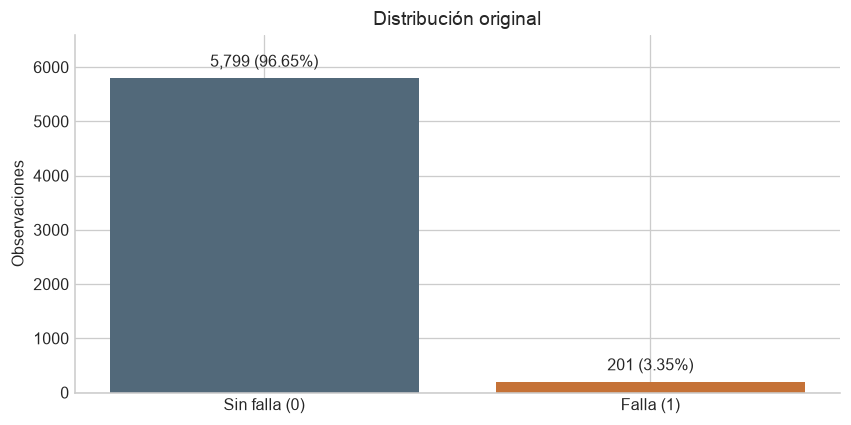

In [2]:
# Creación del dataset 
X, y = make_classification(
    n_samples=6000,
    n_features=12,
    n_informative=6,
    n_redundant=2,
    n_repeated=0,
    n_clusters_per_class=2,
    weights=[0.97, 0.03],
    flip_y=0.01,
    class_sep=0.9,
    random_state=42
)
columnas = [f"sensor_{i}" for i in range(1, 13)]
df = pd.DataFrame(X, columns=columnas)
df['falla'] = y

# Características
X = df[columnas].copy()
y = df['falla'].copy()
conteos = y.value_counts().sort_index()
prevalencia = y.mean()
razon = conteos.loc[0] / conteos.loc[1]
print(f'Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas (12 sensores + objetivo)')
display(pd.DataFrame({'Tipo': df.dtypes.astype(str), 'Faltantes': df.isna().sum()}))
distribucion = pd.DataFrame({'Clase': ['Sin falla (0)', 'Falla (1)'],
                             'Observaciones': conteos.to_numpy(),
                             'Proporción': (conteos / len(y)).to_numpy()})
tabla(distribucion)
print(f'Prevalencia observada: {prevalencia:.2%}; razón negativos/positivos: {razon:.2f}:1')
fig, ax = plt.subplots(figsize=(7.5, 3.8))
barras = ax.bar(distribucion['Clase'], conteos.to_numpy(), color=['#52697a', '#c57237'])
ax.bar_label(barras, labels=[f'{n:,} ({n/len(y):.2%})' for n in conteos], padding=5)
ax.set(title='Distribución original', ylabel='Observaciones', ylim=(0, 6600))
plt.tight_layout()
plt.show()


El dataset contiene 201 fallas entre 6,000 observaciones (3.35%), mientras que los casos restantes corresponden a componentes sin falla. Esto significa que, por cada componente que falla, hay aproximadamente 29 que no presentan fallas. Los 12 sensores son variables numéricas y no presentan valores faltantes, por lo que el principal desafío es identificar un evento poco frecuente en un escenario donde las clases no están perfectamente separadas.

Este desbalance hace que la exactitud pueda resultar engañosa: un modelo que siempre prediga que no habrá fallas alcanzaría cerca del 97% de exactitud, pero sería incapaz de detectar una sola falla. Por esta razón, utilizaremos MCC como métrica principal y kappa de Cohen como complementaria, complementadas con precision y recall para entender cuántas fallas logramos identificar y cuántas falsas alarmas generamos. 

En particular, se prioriza MCC porque mide qué tan bien el modelo distingue entre componentes que fallan y los que no, considerando los aciertos y errores de ambas clases, incluso cuando están desbalanceadas. En cambio, kappa de Cohen evalúa qué tanto coinciden las predicciones con los resultados reales, descontando la coincidencia que se esperaría por azar según las proporciones de cada clase. Así, mientras MCC se enfoca en la capacidad de clasificación del modelo, kappa aporta una medida complementaria del acuerdo alcanzado.

## 3. Partición estratificada

Se reserva 20% como test. La estratificación conserva aproximadamente la prevalencia. Train (4,800) se usa para todos los ajustes y elecciones. Test (1,200) se utiliza después de fijar modelo, umbrales y calibrador.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
particion = pd.DataFrame([
    {'Conjunto': nombre, 'Filas': len(yy), 'Negativos': int((yy == 0).sum()),
     'Positivos': int((yy == 1).sum()), 'Prevalencia': yy.mean()}
    for nombre, yy in [('Train', y_train), ('Test', y_test)]
])
tabla(particion)
assert set(X_train.index).isdisjoint(X_test.index)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(cv.split(X_train, y_train))


,Conjunto,Filas,Negativos,Positivos,Prevalencia
0,Train,4800,4639,161,0.0335
1,Test,1200,1160,40,0.0333


La partición estratificada permitió mantener prácticamente la misma proporción de fallas en ambos conjuntos: 161 casos positivos en entrenamiento (3.35%) y 40 en prueba (3.33%). Esto asegura que ambos conjuntos tengan una distribución similar a la original, sin compartir observaciones.

El conjunto de entrenamiento se utilizará para ajustar y seleccionar los modelos, mientras que el de prueba se reservará para evaluar su desempeño final. Es importante considerar que solo contamos con 40 fallas en test, por lo que cada falla detectada o no detectada representa un cambio de 2.5 puntos porcentuales en el recall. Esto significa que pequeñas diferencias entre modelos deben interpretarse con cautela, especialmente al evaluar la detección de fallas y la calibración de probabilidades.


## 4. Modelos y estrategias de balanceo

Se compara un modelo base sin balanceo con cuatro tratamientos del desbalance, manteniendo los hiperparámetros del clasificador.

### Modelo base

- **Regresión Logística (LR):** se entrena sobre los datos estandarizados, sin aplicar ningún tratamiento de desbalance y con `max_iter=1000`. Se incluye como modelo de referencia por su simplicidad, interpretabilidad y capacidad para establecer una comparación con modelos más complejos.

### Estrategias de balanceo

Se evalúan cuatro estrategias para tratar el desbalance de clases:

- **Random Oversampling:** incrementa la representación de la clase minoritaria mediante la duplicación aleatoria de observaciones existentes.
- **Random Undersampling:** reduce la representación de la clase mayoritaria mediante la eliminación aleatoria de observaciones.
- **SMOTE:** genera observaciones sintéticas de la clase minoritaria a partir de la interpolación entre observaciones vecinas.
- **Ponderación de clases:** asigna pesos diferenciados a las clases durante el entrenamiento, sin modificar la cantidad de observaciones. Regresión Logística utiliza `class_weight="balanced"`.

### Configuración del remuestreo

ROS, RUS y SMOTE conservan semilla 42 y SMOTE optimiza `k_neighbors` entre 3, 5, 7, 9 y 11. La razón positivos/negativos se selecciona entre cinco valores; SMOTE busca conjuntamente los cinco valores de vecinos mediante CV interna; el balanceo completo es un candidato de referencia.


In [4]:
ESTRATEGIAS = {0: 'Sin balanceo', 1: 'Random Oversampling',
               2: 'Random Undersampling', 3: 'SMOTE', 4: 'Ponderación'}


class ConteosRemuestreoMixin:
    """Instrumenta el resultado real de fit_resample sin cambiar el algoritmo."""
    def fit_resample(self, X, y, **params):
        self.conteos_antes_ = {c: int(np.sum(np.asarray(y) == c)) for c in [0, 1]}
        X_res, y_res = super().fit_resample(X, y, **params)
        self.conteos_despues_ = {c: int(np.sum(np.asarray(y_res) == c)) for c in [0, 1]}
        self.n_entrada_ = len(y)
        self.n_salida_ = len(y_res)
        # La comprobación usa el plan de imbalanced-learn, que incorpora sus redondeos.
        for clase in [0, 1]:
            esperado = (self.conteos_antes_[clase] + self.sampling_strategy_.get(clase, 0)
                        if self._sampling_type == 'over-sampling'
                        else self.sampling_strategy_.get(clase, self.conteos_antes_[clase]))
            assert self.conteos_despues_[clase] == esperado
        assert self.n_salida_ == sum(self.conteos_despues_.values())
        return X_res, y_res

class RandomOverSamplerAuditado(ConteosRemuestreoMixin, RandomOverSampler):
    pass

class RandomUnderSamplerAuditado(ConteosRemuestreoMixin, RandomUnderSampler):
    pass

class SMOTEAuditado(ConteosRemuestreoMixin, SMOTE):
    pass

def construir_modelo(estrategia, sampling_strategy=1.0, k_neighbors=5):
    pasos = [('scaler', StandardScaler())]
    muestreadores = {
        1: RandomOverSamplerAuditado(sampling_strategy=sampling_strategy, random_state=42),
        2: RandomUnderSamplerAuditado(sampling_strategy=sampling_strategy, random_state=42),
        3: SMOTEAuditado(sampling_strategy=sampling_strategy, random_state=42, k_neighbors=k_neighbors),
    }
    if estrategia in muestreadores:
        pasos.append(('sampler', muestreadores[estrategia]))
    modelo = LogisticRegression(max_iter=1000, random_state=42,
                                class_weight='balanced' if estrategia == 4 else None)
    return Pipeline(pasos + [('modelo', modelo)])

AUDITORIA_ESCALADO = []

def verificar_escalado_fit(estimador, datos_fit, datos_reservados=None):
    """Contrasta las estadísticas del scaler con su subentrenamiento real."""
    if 'scaler' not in estimador.named_steps:
        return
    scaler = estimador.named_steps['scaler']
    assert isinstance(scaler, StandardScaler)
    assert list(estimador.named_steps)[0] == 'scaler'
    assert int(scaler.n_samples_seen_) == len(datos_fit)
    valores = np.asarray(datos_fit, dtype=float)
    np.testing.assert_allclose(scaler.mean_, valores.mean(axis=0), rtol=1e-10, atol=1e-12)
    np.testing.assert_allclose(scaler.var_, valores.var(axis=0), rtol=1e-10, atol=1e-12)
    if datos_reservados is not None:
        assert set(datos_fit.index).isdisjoint(datos_reservados.index)
    if 'sampler' in estimador.named_steps:
        assert estimador.named_steps['sampler'].n_entrada_ == len(datos_fit)
    AUDITORIA_ESCALADO.append({
        'N_fit':len(datos_fit),
        'N_reservados':0 if datos_reservados is None else len(datos_reservados),
        'SMOTE':isinstance(estimador.named_steps.get('sampler'), SMOTEAuditado),
    })

def probabilidad_positiva(modelo, datos):
    """Localiza la columna de la clase 1; no presupone su posición."""
    idx = np.flatnonzero(np.asarray(modelo.classes_) == 1)
    assert len(idx) == 1
    p = np.asarray(modelo.predict_proba(datos))[:, idx[0]]
    assert p.shape == (len(datos),)
    assert np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    return p


# La malla es predefinida; el óptimo se refiere únicamente a sus candidatos.
MALLA_UMBRALES = np.linspace(0.005, 0.995, 199)

def metricas_decision(verdad, pred):
    return {
        'Accuracy': accuracy_score(verdad, pred),
        'MCC': matthews_corrcoef(verdad, pred),
        'Kappa': cohen_kappa_score(verdad, pred),
        'Precision': precision_score(verdad, pred, zero_division=0),
        'Recall': recall_score(verdad, pred, zero_division=0),
        'F1': f1_score(verdad, pred, zero_division=0),
        'Pred_positivas': int(np.sum(pred)),
    }

def evaluar_probabilidades(verdad, p):
    p = np.asarray(p, dtype=float)
    return {
        'ROC_AUC': roc_auc_score(verdad, p),
        'AP': average_precision_score(verdad, p),
        'Brier': brier_score_loss(verdad, p),
        'LogLoss': log_loss(verdad, np.column_stack([1-p, p]), labels=[0, 1]),
        'Prob_media': np.mean(p), 'Prevalencia': np.mean(verdad),
    }

def evaluar(verdad, p, umbral):
    """Exige un umbral explícito seleccionado exclusivamente con train."""
    assert np.isfinite(umbral) and 0 <= umbral <= 1
    pred = (np.asarray(p) >= umbral).astype(int)
    return {'Umbral': float(umbral), **metricas_decision(verdad, pred),
            **evaluar_probabilidades(verdad, p)}

def curva_mcc(verdad, p):
    return np.array([matthews_corrcoef(verdad, np.asarray(p) >= t)
                     for t in MALLA_UMBRALES])

def seleccionar_umbral(verdad, p):
    puntuaciones = curva_mcc(verdad, p)
    # Ante empate numérico de MCC, el mayor umbral evita alarmas adicionales.
    candidatos = np.flatnonzero(np.isclose(puntuaciones, puntuaciones.max(), rtol=0, atol=1e-12))
    return float(MALLA_UMBRALES[candidatos[-1]])


def generar_oof(plantilla, datos, etiquetas, n_splits=5, devolver_folds=False):
    """Predicciones OOF locales; devuelve los folds para reutilizar la evaluación."""
    interna = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    p = np.full(len(etiquetas), np.nan)
    asignacion = np.full(len(etiquetas), -1, dtype=int)
    for fold, (it, iv) in enumerate(interna.split(datos, etiquetas), start=1):
        assert set(it).isdisjoint(iv)
        estimador = clone(plantilla)
        if 'scaler' in estimador.named_steps:
            assert not hasattr(estimador.named_steps['scaler'], 'mean_')
        estimador.fit(datos.iloc[it], etiquetas.iloc[it])
        p[iv] = probabilidad_positiva(estimador, datos.iloc[iv])
        verificar_escalado_fit(estimador, datos.iloc[it], datos.iloc[iv])
        assert np.all(asignacion[iv] == -1)
        asignacion[iv] = fold
    assert np.all(asignacion > 0) and np.isfinite(p).all()
    return (p, asignacion) if devolver_folds else p


### Búsqueda de intensidad y vecinos

ROS y RUS evalúan cinco sampling_strategy: [0.05, 0.10, 0.25, 0.50, 1.00]. SMOTE evalúa su producto cartesiano con k_neighbors=[3, 5, 7, 9, 11]: **25 parejas**, seleccionadas conjuntamente. sampling_strategy es la razón positivos/negativos después del remuestreo; k_neighbors controla el vecindario usado para interpolar y no la cantidad de ejemplos sintéticos.

Cada candidato genera OOF con tres folds internos. Se elige su umbral maximizando MCC OOF agrupado y se calcula MCC de cada fold con ese umbral. Se ordena por MCC interno medio descendente, SD ascendente, sampling_strategy ascendente y, solo para SMOTE, k_neighbors ascendente. Estos scores sirven para ajustar y pueden ser optimistas; los cinco folds externos reservados evalúan el procedimiento completo.

La factibilidad se contrasta en todos los subentrenamientos internos y en el reajuste local. Los candidatos inválidos conservan su motivo; nunca se reemplazan silenciosamente. La caché identifica los datos y etiquetas de ajuste, ambas mallas, los parámetros restantes y los folds internos.


In [5]:
SAMPLING_STRATEGIES = [0.05, 0.10, 0.25, 0.50, 1.00]
K_NEIGHBORS = [3, 5, 7, 9, 11]
FOLDS_BUSQUEDA = 3
BUSQUEDAS_CACHE = {}
CACHE_HITS = 0
AUDITORIA_CALIBRACION = []

def huella_datos(datos, etiquetas):
    h = hashlib.sha256(pd.util.hash_pandas_object(datos, index=True).to_numpy().tobytes())
    h.update(np.asarray(etiquetas, dtype=np.int64).tobytes())
    return h.hexdigest()

def parametros_remuestreo(resultado):
    parametros = {'sampler__sampling_strategy': resultado['sampling_strategy']}
    if resultado['k_neighbors'] is not None:
        parametros['sampler__k_neighbors'] = int(resultado['k_neighbors'])
    return parametros

def factibilidad_sampling(plantilla, etiquetas, valor, k_neighbors=None):
    sampler = plantilla.named_steps['sampler']
    y_local = np.asarray(etiquetas)
    negativos = int(np.sum(y_local == 0)); positivos = int(np.sum(y_local == 1))
    if not (0 < positivos < negativos):
        return False, 'Se requieren ambas clases y falla=1 como minoritaria.'
    if not (positivos/negativos < valor <= 1):
        return False, 'La razón debe superar positivos/negativos original y no exceder 1.'
    try:
        plan = check_sampling_strategy(float(valor), y_local, sampler._sampling_type)
        if sampler._sampling_type == 'under-sampling' and plan.get(0, negativos) >= negativos:
            return False, 'El redondeo no permite eliminar ninguna observación mayoritaria.'
        if isinstance(sampler, SMOTE):
            k = sampler.k_neighbors if k_neighbors is None else k_neighbors
            if not isinstance(k, (int, np.integer)) or k < 1:
                return False, f'k_neighbors={k} debe ser un entero positivo.'
            if positivos <= k:
                return False, f'SMOTE: {positivos} positivos no bastan para k_neighbors={k}.'
    except ValueError as exc:
        return False, str(exc)
    return True, ''

def buscar_sampling(mid, plantilla, datos, etiquetas, n_splits=3):
    """Selecciona la pareja de SMOTE solo con los datos locales recibidos."""
    global CACHE_HITS
    es_smote = isinstance(plantilla.named_steps['sampler'], SMOTE)
    firma = repr(sorted((k, repr(v)) for k, v in plantilla.get_params(deep=True).items()
                        if '__' in k and k not in
                        {'sampler__sampling_strategy', 'sampler__k_neighbors'}))
    huella = huella_datos(datos, etiquetas)
    clave = ('smote-conjunto-v1', mid, huella, n_splits,
             tuple(SAMPLING_STRATEGIES), tuple(K_NEIGHBORS), firma)
    if clave in BUSQUEDAS_CACHE:
        CACHE_HITS += 1
        return BUSQUEDAS_CACHE[clave]
    interna = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
    particiones = list(interna.split(datos, etiquetas))
    candidatos = [(float(a), k) for a in SAMPLING_STRATEGIES
                  for k in (K_NEIGHBORS if es_smote else [None])]
    filas, predicciones = [], {}
    for valor, k in candidatos:
        motivos = []
        for fold, (it, iv) in enumerate(particiones, start=1):
            assert set(it).isdisjoint(iv)
            ok, motivo = factibilidad_sampling(plantilla, etiquetas.iloc[it], valor, k)
            if not ok: motivos.append(f'Fold interno {fold}: {motivo}')
        ok, motivo = factibilidad_sampling(plantilla, etiquetas, valor, k)
        if not ok: motivos.append(f'Reentrenamiento local: {motivo}')
        fila = {'ID': mid, 'sampling_strategy': valor,
                'k_neighbors': np.nan if k is None else int(k),
                'Factible': not motivos, 'Motivo': ' | '.join(motivos),
                'N_ajuste': len(etiquetas), 'Huella_ajuste': huella}
        if motivos:
            filas.append(fila)
            continue
        candidato = clone(plantilla).set_params(**parametros_remuestreo(
            {'sampling_strategy':valor, 'k_neighbors':k}))
        try:
            p, asignacion = generar_oof(candidato, datos, etiquetas,
                                        n_splits=n_splits, devolver_folds=True)
        except ValueError as exc:
            fila.update(Factible=False, Motivo='Error de remuestreo/ajuste: '+str(exc))
            filas.append(fila)
            continue
        t = seleccionar_umbral(etiquetas, p)
        mccs = [matthews_corrcoef(np.asarray(etiquetas)[asignacion == f], p[asignacion == f] >= t)
                for f in range(1, n_splits+1)]
        fila.update(Umbral_OOF=t, MCC_interno_media=float(np.mean(mccs)),
                    MCC_interno_sd=float(np.std(mccs, ddof=1)),
                    MCC_OOF=matthews_corrcoef(etiquetas, p >= t),
                    **{f'MCC_interno_{j}':m for j,m in enumerate(mccs, start=1)})
        filas.append(fila)
        predicciones[(valor, k)] = p
    tabla_busqueda = pd.DataFrame(filas)
    factibles = tabla_busqueda.loc[tabla_busqueda['Factible']]
    if factibles.empty:
        raise ValueError(f'{mid}: ningún candidato factible. '+tabla_busqueda['Motivo'].str.cat(sep=' | '))
    criterios = ['MCC_interno_media', 'MCC_interno_sd', 'sampling_strategy']
    if es_smote: criterios.append('k_neighbors')
    mejor = factibles.sort_values(criterios, ascending=[False]+[True]*(len(criterios)-1),
                                 kind='stable').iloc[0]
    valor = float(mejor['sampling_strategy'])
    k = int(mejor['k_neighbors']) if es_smote else None
    mascara_k = (tabla_busqueda['k_neighbors'].eq(k) if es_smote
                 else tabla_busqueda['k_neighbors'].isna())
    tabla_busqueda['Seleccionado'] = tabla_busqueda['sampling_strategy'].eq(valor) & mascara_k
    assert tabla_busqueda['Seleccionado'].sum() == 1
    resultado = {'sampling_strategy':valor, 'k_neighbors':k,
                 'umbral':float(mejor['Umbral_OOF']), 'oof':predicciones[(valor, k)],
                 'tabla':tabla_busqueda, 'huella':huella, 'n_ajuste':len(etiquetas)}
    BUSQUEDAS_CACHE[clave] = resultado
    return resultado

class SeleccionSamplingCV(ClassifierMixin, BaseEstimator):
    """Busca ambos parámetros de SMOTE solo con las filas recibidas por fit."""
    def __init__(self, plantilla=None, mid=None, n_splits=3):
        self.plantilla = plantilla
        self.mid = mid
        self.n_splits = n_splits

    def fit(self, X, y):
        datos = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X)
        etiquetas = pd.Series(np.asarray(y), index=datos.index)
        resultado = buscar_sampling(self.mid, self.plantilla, datos, etiquetas, self.n_splits)
        self.sampling_strategy_ = resultado['sampling_strategy']
        self.k_neighbors_ = resultado['k_neighbors']
        self.umbral_ = resultado['umbral']
        self.estimador_ = clone(self.plantilla).set_params(
            **parametros_remuestreo(resultado)).fit(datos, etiquetas)
        verificar_escalado_fit(self.estimador_, datos)
        self.classes_ = self.estimador_.classes_
        self.n_features_in_ = self.estimador_.n_features_in_
        self.huella_ajuste_ = resultado['huella']
        AUDITORIA_CALIBRACION.append({'ID':self.mid, 'N_ajuste':len(y),
            'Huella_ajuste':self.huella_ajuste_, 'sampling_strategy':self.sampling_strategy_,
            'k_neighbors':self.k_neighbors_})
        return self

    def predict_proba(self, X):
        return self.estimador_.predict_proba(X)

    def predict(self, X):
        return (probabilidad_positiva(self, X) >= self.umbral_).astype(int)


### Configuraciones experimentales

In [6]:
# Cada ID apunta a un pipeline sin entrenar; CV lo clona en cada fold.
modelos = {f'{FAMILIA}_{j}': construir_modelo(j) for j in range(5)}
catalogo = pd.DataFrame([
    {'ID':mid, 'Familia':FAMILIA, 'Modelo':NOMBRE_MODELO,
     'Estrategia':ESTRATEGIAS[int(mid[-1])],
     'Tratamiento':'class_weight="balanced"' if mid.endswith('_4') else ESTRATEGIAS[int(mid[-1])]}
    for mid in modelos
]).set_index('ID')
display(catalogo)


,Familia,Modelo,Estrategia,Tratamiento
ID,,,,
LR_0,LR,Regresión logística,Sin balanceo,Sin balanceo
LR_1,LR,Regresión logística,Random Oversampling,Random Oversampling
LR_2,LR,Regresión logística,Random Undersampling,Random Undersampling
LR_3,LR,Regresión logística,SMOTE,SMOTE
LR_4,LR,Regresión logística,Ponderación,"class_weight=""balanced"""


El catálogo distingue cinco procedimientos de Regresión logística: un baseline y cuatro tratamientos del desbalance. **LR_0** permite evaluar cuánto aporta balancear frente al mismo algoritmo sin ese tratamiento. Los IDs 1 a 3 buscan la intensidad de remuestreo y el ID 4 modifica los pesos de entrenamiento. Generar ejemplos, descartar negativos y ponderar errores cambian el aprendizaje por vías diferentes.


## 5. Validación cruzada anidada

Se conservan cinco folds externos estratificados. En ROS, RUS y SMOTE, cada subentrenamiento externo optimiza cinco sampling_strategy con tres folds internos; SMOTE evalúa conjuntamente sus 25 parejas de intensidad y vecinos. Para cada candidato se selecciona el umbral mediante MCC OOF agrupado; el criterio de intensidad es MCC interno medio, menor SD, menor razón y, solo para SMOTE, menor k_neighbors. Esos scores son resultados de ajuste. Las dos configuraciones sin remuestreo conservan cinco folds internos para ajustar su umbral.

Cada pipeline se reajusta con el subentrenamiento externo y se evalúa en el fold reservado. Las 25 evaluaciones estiman el procedimiento completo. La configuración ganadora se elige por MCC externo medio, menor SD y después ID.

prob_oof contiene las predicciones externas del procedimiento; prob_oof_final contiene las OOF de la configuración final. Para los tres procedimientos con remuestreo se reutilizan tres folds de la búsqueda final; para los otros dos se conservan sus OOF externas de cinco folds. Las comparaciones principales siempre usan los mismos cinco folds externos.


In [7]:
filas_cv, filas_auditoria, busquedas_externas = [], [], []
prob_oof = {}
for mid, plantilla in modelos.items():
    p_oof = np.full(len(y_train), np.nan)
    for fold, (it, iv) in enumerate(folds, start=1):
        Xt, Xv = X_train.iloc[it], X_train.iloc[iv]
        yt, yv = y_train.iloc[it], y_train.iloc[iv]
        assert set(Xt.index).isdisjoint(Xv.index)
        valor, valor_k = np.nan, np.nan
        if 'sampler' in plantilla.named_steps:
            busqueda = buscar_sampling(mid, plantilla, Xt, yt, FOLDS_BUSQUEDA)
            valor = busqueda['sampling_strategy']
            valor_k = np.nan if busqueda['k_neighbors'] is None else busqueda['k_neighbors']
            umbral_fold = busqueda['umbral']
            registro = busqueda['tabla'].copy()
            registro['Fold_externo'] = fold
            busquedas_externas.append(registro)
            ajustable = clone(plantilla).set_params(**parametros_remuestreo(busqueda))
        else:
            p_interna = generar_oof(plantilla, Xt, yt)
            umbral_fold = seleccionar_umbral(yt, p_interna)
            ajustable = clone(plantilla)
        estimador = ajustable.fit(Xt, yt)
        p = probabilidad_positiva(estimador, Xv)
        verificar_escalado_fit(estimador, Xt, Xv)
        p_oof[iv] = p
        filas_cv.append({'ID':mid, 'Fold':fold, 'sampling_strategy_seleccionado':valor, 'k_neighbors':valor_k,
                          **evaluar(yv, p, umbral_fold)})
        n_scaler = np.nan
        if 'scaler' in estimador.named_steps:
            n_scaler = int(estimador.named_steps['scaler'].n_samples_seen_)
            assert n_scaler == len(it)
        antes = {c:int((yt == c).sum()) for c in [0,1]}
        despues = antes.copy()
        if 'sampler' in estimador.named_steps:
            sampler = estimador.named_steps['sampler']
            assert np.isclose(sampler.sampling_strategy, valor)
            if isinstance(sampler, SMOTE):
                assert sampler.k_neighbors == valor_k
            assert sampler.n_entrada_ == len(it)
            assert sampler.conteos_antes_ == antes
            despues = sampler.conteos_despues_.copy()
            if hasattr(sampler, 'sample_indices_'):
                assert sampler.sample_indices_.max() < len(it)
        filas_auditoria.append({'ID':mid, 'Fold':fold, 'N_subtrain':len(it),
            'N_validacion':len(iv), 'Pos_subtrain':int(yt.sum()), 'Pos_validacion':int(yv.sum()),
            'Umbral_interno':umbral_fold, 'N_scaler':n_scaler,
            'N_fit_clasificador':sum(despues.values()),
            'sampling_strategy_seleccionado':valor, 'k_neighbors':valor_k,
            'N_positivos_antes':antes[1], 'N_negativos_antes':antes[0],
            'N_positivos_despues':despues[1], 'N_negativos_despues':despues[0],
            'ratio_positivo_negativo_despues':despues[1]/despues[0]})
    assert np.isfinite(p_oof).all()
    prob_oof[mid] = p_oof
    print(f'{mid}: cinco evaluaciones externas completadas')
resultados_cv = pd.DataFrame(filas_cv)
auditoria_cv = pd.DataFrame(filas_auditoria)
resultados_busqueda_externa = pd.concat(busquedas_externas, ignore_index=True)
assert len(resultados_cv) == 25
print('MCC individual de los cinco folds externos')
tabla(resultados_cv.pivot(index='ID', columns='Fold', values='MCC').reindex(modelos))
print('Auditoría del remuestreo realmente ejecutado')
tabla(auditoria_cv[['ID','Fold','N_subtrain','N_validacion','N_scaler','sampling_strategy_seleccionado','k_neighbors',
    'N_positivos_antes','N_negativos_antes','N_positivos_despues','N_negativos_despues',
    'ratio_positivo_negativo_despues','N_fit_clasificador']])
print('Candidatos internos no factibles en CV externa')
display(resultados_busqueda_externa.loc[~resultados_busqueda_externa['Factible'],
    ['ID','Fold_externo','sampling_strategy','k_neighbors','Motivo']])
print('Umbrales elegidos sin usar la validación externa')
tabla(resultados_cv.pivot(index='ID', columns='Fold', values='Umbral').reindex(modelos))


LR_0: cinco evaluaciones externas completadas
LR_1: cinco evaluaciones externas completadas
LR_2: cinco evaluaciones externas completadas
LR_3: cinco evaluaciones externas completadas
LR_4: cinco evaluaciones externas completadas
MCC individual de los cinco folds externos


Fold,1,2,3,4,5
ID,,,,,
LR_0,0.3883,0.3981,0.3245,0.4002,0.4528
LR_1,0.3689,0.3980,0.2425,0.3980,0.4262
LR_2,0.3402,0.4483,0.3291,0.3790,0.4037
LR_3,0.3669,0.4483,0.3245,0.4080,0.4092
LR_4,0.2094,0.3030,0.2757,0.3377,0.3638


Auditoría del remuestreo realmente ejecutado


,ID,Fold,N_subtrain,N_validacion,N_scaler,sampling_strategy_seleccionado,k_neighbors,N_positivos_antes,N_negativos_antes,N_positivos_despues,N_negativos_despues,ratio_positivo_negativo_despues,N_fit_clasificador
0,LR_0,1,3840,960,3840,N/A,N/A,129,3711,129,3711,0.0348,3840
1,LR_0,2,3840,960,3840,N/A,N/A,129,3711,129,3711,0.0348,3840
2,LR_0,3,3840,960,3840,N/A,N/A,129,3711,129,3711,0.0348,3840
3,LR_0,4,3840,960,3840,N/A,N/A,129,3711,129,3711,0.0348,3840
4,LR_0,5,3840,960,3840,N/A,N/A,128,3712,128,3712,0.0345,3840
5,LR_1,1,3840,960,3840,0.0500,N/A,129,3711,185,3711,0.0499,3896
6,LR_1,2,3840,960,3840,0.0500,N/A,129,3711,185,3711,0.0499,3896
7,LR_1,3,3840,960,3840,0.0500,N/A,129,3711,185,3711,0.0499,3896
8,LR_1,4,3840,960,3840,0.0500,N/A,129,3711,185,3711,0.0499,3896
9,LR_1,5,3840,960,3840,0.0500,N/A,128,3712,185,3712,0.0498,3897


Candidatos internos no factibles en CV externa


,ID,Fold_externo,sampling_strategy,k_neighbors,Motivo


Umbrales elegidos sin usar la validación externa


Fold,1,2,3,4,5
ID,,,,,
LR_0,0.2100,0.2600,0.2250,0.1950,0.2050
LR_1,0.3100,0.2850,0.3050,0.3050,0.2200
LR_2,0.2500,0.3250,0.2950,0.2550,0.2050
LR_3,0.2500,0.3650,0.2900,0.2900,0.2250
LR_4,0.7300,0.7350,0.8250,0.7450,0.7450


Las tres técnicas eligieron sampling_strategy=0.05 en los cinco subentrenamientos externos. SMOTE seleccionó **k_neighbors=[5, 7, 5, 5, 7]**, respectivamente. Cada pareja se eligió con los tres folds internos de su subentrenamiento, no con las etiquetas externas.

La auditoría conserva los conteos reales antes/después, el tamaño del escalador y ambos parámetros. Los **175 registros de candidatos externos** fueron factibles: 25 ROS, 25 RUS y 125 SMOTE. La variación de vecinos confirma que la CV externa evalúa la búsqueda conjunta completa y no una pareja fija para todos los folds.


## 6. Optimización final de sampling_strategy y vecinos de SMOTE

Se repite la búsqueda con las 4,800 filas de train: cinco candidatos ROS, cinco RUS y 25 parejas SMOTE, **35 candidatos**. Se conservan los mismos desempates y se reutilizan las OOF de la pareja ganadora para fijar su umbral. El resultado final no se decide por votación de los folds externos.


In [8]:
busquedas_finales = {}
sampling_final = {mid:np.nan for mid in modelos}
sampling_strategy_final = sampling_final
k_neighbors_final = {mid:np.nan for mid in modelos}
prob_oof_final = {}
filas_busqueda_final = []
for mid, plantilla in list(modelos.items()):
    if 'sampler' in plantilla.named_steps:
        busqueda = buscar_sampling(mid, plantilla, X_train, y_train, FOLDS_BUSQUEDA)
        busquedas_finales[mid] = busqueda
        sampling_final[mid] = busqueda['sampling_strategy']
        k_neighbors_final[mid] = np.nan if busqueda['k_neighbors'] is None else busqueda['k_neighbors']
        modelos[mid] = clone(plantilla).set_params(**parametros_remuestreo(busqueda))
        prob_oof_final[mid] = busqueda['oof'].copy()
        filas_busqueda_final.append(busqueda['tabla'].copy())
    else:
        prob_oof_final[mid] = prob_oof[mid].copy()
umbrales_fijados = {mid:seleccionar_umbral(y_train, p) for mid,p in prob_oof_final.items()}
resumen_busqueda_final = pd.concat(filas_busqueda_final, ignore_index=True)
resumen_busqueda_final['Familia'] = resumen_busqueda_final['ID'].str.split('_').str[0]
resumen_busqueda_final['Estrategia'] = resumen_busqueda_final['ID'].map(catalogo['Estrategia'])
for familia in [FAMILIA]:
    print(f'{familia}')
    tabla(resumen_busqueda_final.loc[resumen_busqueda_final['Familia'] == familia,
        ['ID','Estrategia','sampling_strategy','k_neighbors','Factible','Umbral_OOF','MCC_interno_media',
         'MCC_interno_sd','Seleccionado','Motivo']])

COLORES_MUESTREO = {1:'#087f8c',2:'#b45b78',3:'#7862a3'}
def graficar_intensidad(familia):
    fig, ax = plt.subplots(figsize=(10,5))
    for estrategia in [1,2]:
        mid = f'{familia}_{estrategia}'
        datos = resumen_busqueda_final.loc[resumen_busqueda_final['ID'] == mid].sort_values('sampling_strategy')
        validos = datos.loc[datos['Factible']]
        color = COLORES_MUESTREO[estrategia]
        nombre = {1:'Sobremuestreo aleatorio',2:'Submuestreo aleatorio'}[estrategia]
        ax.errorbar(validos['sampling_strategy'],validos['MCC_interno_media'],
                     yerr=validos['MCC_interno_sd'],color=color,marker='o',capsize=4,label=nombre)
        mejor = validos.loc[validos['Seleccionado']].iloc[0]
        ax.scatter(mejor['sampling_strategy'],mejor['MCC_interno_media'],s=150,marker='*',
                    color=color,edgecolor='black',linewidth=0.6,zorder=5,
                    label=f'{mid} elegido: {mejor["sampling_strategy"]:.2f}')
        for _,invalido in datos.loc[~datos['Factible']].iterrows():
            ax.annotate('No factible',xy=(invalido['sampling_strategy'],0.02),
                         xycoords=('data','axes fraction'),rotation=90,color=color,fontsize=8)
    ax.set_xticks(SAMPLING_STRATEGIES,[f'{v:.2f}' for v in SAMPLING_STRATEGIES])
    ax.set(xlabel='sampling_strategy · positivos/negativos después de remuestrear',
           ylabel='MCC interno medio ± SD (tres folds)',
           title=NOMBRE_MODELO+
                 ' | Intensidad de balanceo\nBúsqueda final de train · scores internos de ajuste')
    ax.legend(fontsize=8,ncol=2,loc='best')
    plt.tight_layout();plt.show()


LR


,ID,Estrategia,sampling_strategy,k_neighbors,Factible,Umbral_OOF,MCC_interno_media,MCC_interno_sd,Seleccionado,Motivo
0,LR_1,Random Oversampling,0.0500,N/A,True,0.2950,0.3919,0.0183,True,
1,LR_1,Random Oversampling,0.1000,N/A,True,0.3600,0.3761,0.0279,False,
2,LR_1,Random Oversampling,0.2500,N/A,True,0.6350,0.3490,0.0234,False,
3,LR_1,Random Oversampling,0.5000,N/A,True,0.7450,0.3374,0.0150,False,
4,LR_1,Random Oversampling,1.0000,N/A,True,0.8450,0.3167,0.0097,False,
5,LR_2,Random Undersampling,0.0500,N/A,True,0.2900,0.3813,0.0078,True,
6,LR_2,Random Undersampling,0.1000,N/A,True,0.4850,0.3745,0.0196,False,
7,LR_2,Random Undersampling,0.2500,N/A,True,0.6150,0.3529,0.0099,False,
8,LR_2,Random Undersampling,0.5000,N/A,True,0.6750,0.3219,0.0120,False,
9,LR_2,Random Undersampling,1.0000,N/A,True,0.7650,0.3112,0.0282,False,


La búsqueda final reúne **35 candidatos**: cinco ROS, cinco RUS y 25 parejas SMOTE; todos fueron factibles con train. El reajuste usa las 4,800 observaciones y los mismos criterios internos, sin votar los resultados de los folds externos.

ROS, RUS y SMOTE conservan sampling_strategy=0.05. La pareja final de SMOTE es (0.05, 3 vecinos). Las OOF reutilizadas para el umbral de SMOTE son exactamente las de esa pareja ganadora. Las curvas ROS/RUS y el heatmap SMOTE describen ajuste interno; el desempeño se estima por separado en los cinco folds externos.


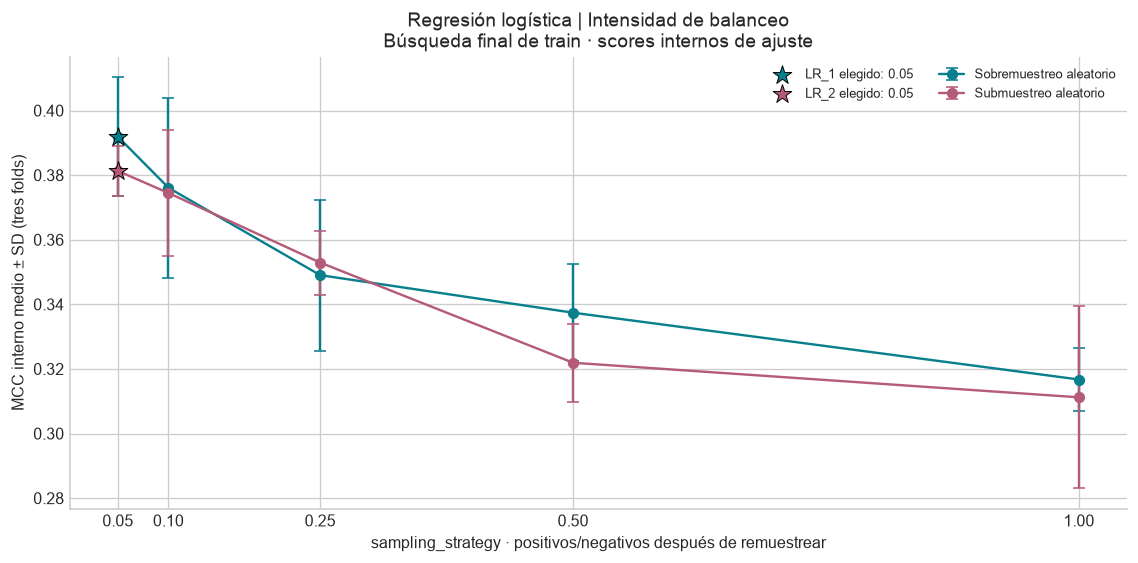

In [9]:
graficar_intensidad('LR')

La gráfica conserva ROS y RUS, que eligen sampling_strategy=0.05. Sus máximos internos son **0.3919** y **0.3813**, con mejoras de **0.0752** y **0.0701** frente a balanceo completo. Aumentar el remuestreo no mejoró su criterio interno en esta malla.

SMOTE se presenta en el heatmap siguiente porque ahora intervienen dos hiperparámetros. Los valores de ambas figuras son scores internos de ajuste, no nuevas estimaciones independientes de desempeño.


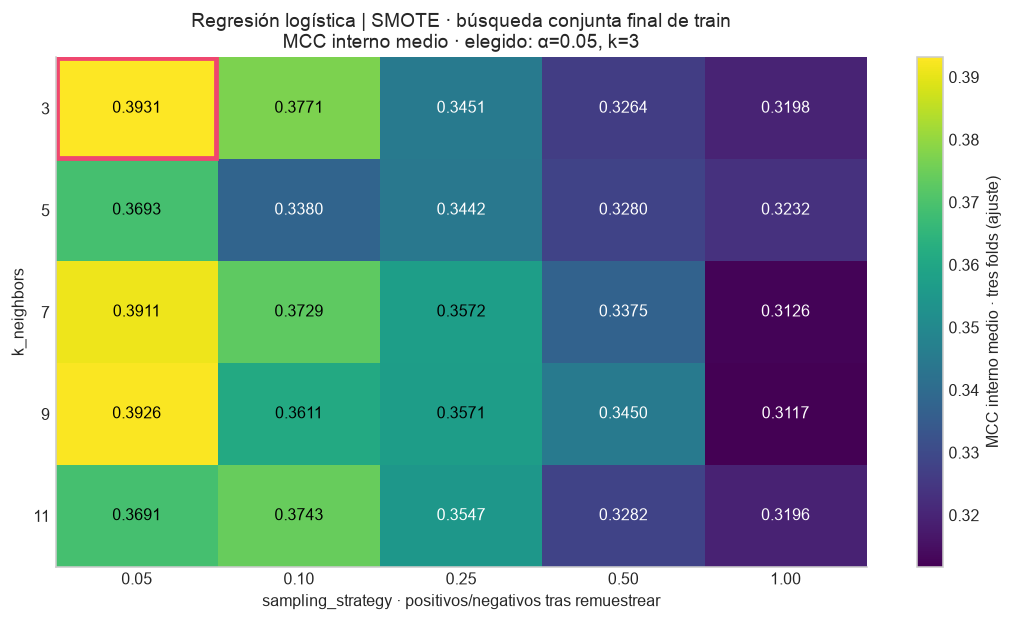

In [10]:
# Scores de ajuste: cada celda usa tres folds internos de train.
mid_smote = f'{FAMILIA}_3'
datos_smote = resumen_busqueda_final.loc[resumen_busqueda_final['ID'] == mid_smote]
matriz = datos_smote.pivot(index='k_neighbors', columns='sampling_strategy',
                           values='MCC_interno_media').reindex(index=K_NEIGHBORS, columns=SAMPLING_STRATEGIES)
factible = datos_smote.pivot(index='k_neighbors', columns='sampling_strategy',
                            values='Factible').reindex(index=K_NEIGHBORS, columns=SAMPLING_STRATEGIES)
valores = matriz.to_numpy(dtype=float)
mascara = (~factible.to_numpy(dtype=bool)) | ~np.isfinite(valores)
cmap = plt.get_cmap('viridis').copy()
cmap.set_bad('#d9d9d9')
fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.grid(False)
im = ax.imshow(np.ma.array(valores, mask=mascara), cmap=cmap, aspect='auto')
for i, k in enumerate(K_NEIGHBORS):
    for j, a in enumerate(SAMPLING_STRATEGIES):
        if mascara[i, j]:
            ax.text(j, i, 'No factible', ha='center', va='center', fontsize=8, color='#333333')
        else:
            color = 'white' if im.norm(valores[i, j]) < .55 else 'black'
            ax.text(j, i, f'{valores[i,j]:.4f}', ha='center', va='center', color=color)
mejor = datos_smote.loc[datos_smote['Seleccionado']].iloc[0]
j = SAMPLING_STRATEGIES.index(float(mejor['sampling_strategy']))
i = K_NEIGHBORS.index(int(mejor['k_neighbors']))
from matplotlib.patches import Rectangle
ax.add_patch(Rectangle((j-.49, i-.49), .98, .98, fill=False, edgecolor='#ef476f', lw=3))
ax.set_xticks(range(len(SAMPLING_STRATEGIES)), [f'{a:.2f}' for a in SAMPLING_STRATEGIES])
ax.set_yticks(range(len(K_NEIGHBORS)), K_NEIGHBORS)
ax.set(xlabel='sampling_strategy · positivos/negativos tras remuestrear', ylabel='k_neighbors',
       title=f'{NOMBRE_MODELO} | SMOTE · búsqueda conjunta final de train\n'
             f'MCC interno medio · elegido: α={mejor["sampling_strategy"]:.2f}, k={int(mejor["k_neighbors"])}')
fig.colorbar(im, ax=ax, label='MCC interno medio · tres folds (ajuste)')
plt.tight_layout()
plt.show()


**SMOTE: mejor pareja interna (sampling_strategy=0.05, k_neighbors=3)**, con MCC medio **0.3931 ± 0.0340**. A esa intensidad, cinco vecinos producen **0.3693**; la elección conjunta mejora el score interno en **0.0238**. Para k=3, pasar a balanceo completo reduce el MCC interno a **0.3198**.

La respuesta a los vecinos no es monótona: en 0.05, k=7 y k=9 se acercan al máximo, mientras k=11 queda por debajo. El mejor resultado no requiere más vecinos. La pareja aparece en el extremo inferior de ambas mallas; no se extrapola a valores no evaluados. El borde resalta la selección conjunta, no una búsqueda independiente de cada parámetro. El desempeño externo del procedimiento se presenta en la sección siguiente.


## 7. Comparación de estrategias mediante CV externa

La clasificación se ordena por MCC promedio de los cinco folds externos, con selección interna del umbral en cada fold. Se desempata por menor SD y luego por ID. Kappa, AP, estabilidad y complejidad complementan la interpretación; una diferencia pequeña de medias no demuestra superioridad estadística.

La columna `Umbral_train` documenta el umbral final obtenido con las OOF de todo train. Las métricas de CV se calcularon con los cinco umbrales internos correspondientes a cada subentrenamiento, que se muestran en la auditoría anterior. No se aplicó retrospectivamente el umbral final a las etiquetas de validación para seleccionar modelos.
En las estrategias con remuestreo, cada MCC externo evalúa la búsqueda interna completa: el sampling_strategy puede variar entre folds. `Sampling_train` es el valor elegido en una nueva búsqueda sobre train completo, y `Sampling_por_fold` permite auditar los valores externos sin usarlos como votación para el modelo final.


In [11]:
metricas_cv = ['Accuracy', 'MCC', 'Kappa', 'Precision', 'Recall', 'F1',
               'ROC_AUC', 'AP', 'Brier', 'LogLoss', 'Prob_media', 'Pred_positivas', 'Umbral']
medias_cv = resultados_cv.groupby('ID')[metricas_cv].mean().add_suffix('_CV')
desv_cv = resultados_cv.groupby('ID')[metricas_cv].std(ddof=1).add_suffix('_SD')
resumen_cv = catalogo.join(medias_cv).join(desv_cv)
resumen_cv['Umbral_train'] = pd.Series(umbrales_fijados)
resumen_cv['Sampling_train'] = pd.Series(sampling_final)
resumen_cv['k_neighbors'] = pd.Series(k_neighbors_final)
resumen_cv['k_por_fold'] = resultados_cv.groupby('ID')['k_neighbors'].agg(list)
resumen_cv['Sampling_por_fold'] = resultados_cv.groupby('ID')['sampling_strategy_seleccionado'].agg(list)
resumen_cv = resumen_cv.sort_values(['MCC_CV', 'MCC_SD'], ascending=[False, True], kind='stable')
# El ID resuelve empates exactos tras MCC y desviación.
resumen_cv = resumen_cv.reset_index().sort_values(
    ['MCC_CV', 'MCC_SD', 'ID'], ascending=[False, True, True]).set_index('ID')
columnas_cv = ['Modelo', 'Estrategia', 'MCC_CV', 'MCC_SD', 'Kappa_CV',
               'AP_CV', 'Recall_CV', 'Precision_CV', 'Accuracy_CV', 'F1_CV', 'ROC_AUC_CV', 'Umbral_train', 'Sampling_train', 'k_neighbors']
for familia in [FAMILIA]:
    print(f'Bloque {familia}: ordenado por MCC de CV')
    tabla(resumen_cv[resumen_cv['Familia'] == familia][columnas_cv])

print('Calidad probabilística de CV: menor Brier/Log Loss es mejor')
tabla(resumen_cv[['Estrategia', 'Brier_CV', 'LogLoss_CV', 'Prob_media_CV']])
ganador_id = resumen_cv.index[0]
mejor_kappa_id = resumen_cv['Kappa_CV'].idxmax()
print(f'Ganador MCC fijado: {ganador_id}; mayor kappa promedio: {mejor_kappa_id}')
# MCC descendente, SD ascendente e ID ascendente, como en el original.
mejor_balanceado_id = resumen_cv.loc[
    resumen_cv.index.isin([f'{FAMILIA}_{j}' for j in range(1, 5)])
].index[0]
comparaciones = {FAMILIA: [f'{FAMILIA}_0', mejor_balanceado_id]}
assert len(set(comparaciones[FAMILIA])) == 2
print(f'Comparación principal: {comparaciones[FAMILIA]}')
print('Configuración final y desempeño externo · N/A identifica ausencia de remuestreo')
resumen_configuraciones = resumen_cv[['Modelo','Estrategia','Sampling_train','k_neighbors','Sampling_por_fold','k_por_fold',
                                     'Umbral_train','MCC_CV','MCC_SD','Kappa_CV','AP_CV','Recall_CV']].copy()
resumen_configuraciones['Sampling_train'] = resumen_configuraciones['Sampling_train'].map(
    lambda valor:'N/A' if pd.isna(valor) else f'{valor:.2f}')
resumen_configuraciones['Sampling_por_fold'] = resumen_configuraciones['Sampling_por_fold'].map(
    lambda valores:'N/A' if all(pd.isna(v) for v in valores) else ', '.join(f'{v:.2f}' for v in valores))
resumen_configuraciones['k_por_fold'] = resumen_configuraciones['k_por_fold'].map(
    lambda valores:'N/A' if all(pd.isna(v) for v in valores) else ', '.join(str(int(v)) for v in valores))
tabla(resumen_configuraciones)


Bloque LR: ordenado por MCC de CV


,Modelo,Estrategia,MCC_CV,MCC_SD,Kappa_CV,AP_CV,Recall_CV,Precision_CV,Accuracy_CV,F1_CV,ROC_AUC_CV,Umbral_train,Sampling_train,k_neighbors
ID,,,,,,,,,,,,,,
LR_0,Regresión logística,Sin balanceo,0.3928,0.0458,0.3865,0.3367,0.3727,0.4628,0.9627,0.4053,0.8402,0.2300,N/A,N/A
LR_3,Regresión logística,SMOTE,0.3914,0.0472,0.3873,0.3255,0.3852,0.4444,0.9617,0.4068,0.8415,0.2900,0.0500,3
LR_2,Regresión logística,Random Undersampling,0.3801,0.0485,0.3773,0.3306,0.3911,0.4157,0.9598,0.3978,0.8403,0.2900,0.0500,N/A
LR_1,Regresión logística,Random Oversampling,0.3667,0.0723,0.3640,0.3240,0.3536,0.4246,0.9615,0.3836,0.8468,0.2950,0.0500,N/A
LR_4,Regresión logística,Ponderación,0.2979,0.0598,0.2683,0.2472,0.5148,0.2160,0.9210,0.3027,0.8531,0.8350,N/A,N/A


Calidad probabilística de CV: menor Brier/Log Loss es mejor


,Estrategia,Brier_CV,LogLoss_CV,Prob_media_CV
ID,,,,
LR_0,Sin balanceo,0.0273,0.1126,0.0337
LR_3,SMOTE,0.0278,0.1150,0.0446
LR_2,Random Undersampling,0.0277,0.1151,0.0453
LR_1,Random Oversampling,0.0278,0.1142,0.0444
LR_4,Ponderación,0.1511,0.4649,0.3137


Ganador MCC fijado: LR_0; mayor kappa promedio: LR_3
Comparación principal: ['LR_0', 'LR_3']
Configuración final y desempeño externo · N/A identifica ausencia de remuestreo


,Modelo,Estrategia,Sampling_train,k_neighbors,Sampling_por_fold,k_por_fold,Umbral_train,MCC_CV,MCC_SD,Kappa_CV,AP_CV,Recall_CV
ID,,,,,,,,,,,,
LR_0,Regresión logística,Sin balanceo,N/A,N/A,N/A,N/A,0.2300,0.3928,0.0458,0.3865,0.3367,0.3727
LR_3,Regresión logística,SMOTE,0.05,3,"0.05, 0.05, 0.05, 0.05, 0.05","5, 7, 5, 5, 7",0.2900,0.3914,0.0472,0.3873,0.3255,0.3852
LR_2,Regresión logística,Random Undersampling,0.05,N/A,"0.05, 0.05, 0.05, 0.05, 0.05",N/A,0.2900,0.3801,0.0485,0.3773,0.3306,0.3911
LR_1,Regresión logística,Random Oversampling,0.05,N/A,"0.05, 0.05, 0.05, 0.05, 0.05",N/A,0.2950,0.3667,0.0723,0.3640,0.3240,0.3536
LR_4,Regresión logística,Ponderación,N/A,N/A,N/A,N/A,0.8350,0.2979,0.0598,0.2683,0.2472,0.5148


LR_0 conserva la mayor media externa (**0.3928**). SMOTE con búsqueda conjunta es el mejor balanceado (**LR_3: 0.3914**), seguido de RUS (**0.3801**), ROS (**0.3667**) y ponderación (**0.2979**).

Frente al procedimiento anterior con cinco vecinos fijos, SMOTE pasa de **0.3839 a 0.3914** de MCC externo. Esa mejora observada no cambia la selección: el baseline mantiene una media ligeramente mayor. La mayor malla también aumenta las oportunidades de ajuste; el máximo interno no se utiliza como evidencia de generalización.


In [12]:
# Funciones de presentación: reutilizan las predicciones y métricas originales.
NOMBRES_FAMILIA = {FAMILIA: NOMBRE_MODELO}
COLORES_ROL = ['#32658a', '#c57237']
ESTRATEGIAS_VISUALES = {0: 'Sin balanceo', 1: 'Sobremuestreo aleatorio',
                       2: 'Submuestreo aleatorio', 3: 'SMOTE', 4: 'Ponderación de clases'}
METRICAS_COMPARACION = {
    'MCC': 'MCC', 'Kappa': 'Kappa', 'Precision': 'Precision', 'Recall': 'Recall',
    'F1-score': 'F1', 'Average Precision': 'AP', 'Brier Score': 'Brier', 'Log Loss': 'LogLoss',
}

def etiqueta_config(mid):
    base = f'{mid} · {ESTRATEGIAS_VISUALES[int(mid[-1])]}'
    base += (f' · α={sampling_final[mid]:.2f}' if pd.notna(sampling_final[mid]) else '')
    return base + (f' · k={int(k_neighbors_final[mid])}' if pd.notna(k_neighbors_final[mid]) else '')

def titulo_bloque(familia):
    return f'{NOMBRES_FAMILIA[familia]} | Baseline vs. mejor estrategia de balanceo'

def graficar_mcc_cv(familia):
    ids = comparaciones[familia]
    datos = resumen_cv.loc[ids]
    fig, ax = plt.subplots(figsize=(9.8, 5.0))
    posiciones = np.arange(2)
    barras = ax.bar(posiciones, datos['MCC_CV'], yerr=datos['MCC_SD'],
                    capsize=6, color=COLORES_ROL, alpha=0.85, width=0.55)
    for j, mid in enumerate(ids):
        valores = resultados_cv.loc[resultados_cv['ID'] == mid, 'MCC'].to_numpy()
        ax.scatter(j+np.linspace(-0.14, 0.14, len(valores)), valores,
                    color='#202b33', edgecolor='white', linewidth=0.5, s=40,
                    zorder=4, label='Cinco folds externos' if j == 0 else None)
        altura = max(float(valores.max()), datos.loc[mid, 'MCC_CV']+datos.loc[mid, 'MCC_SD'])
        ax.text(j, altura+0.025,
                f'{datos.loc[mid, "MCC_CV"]:.3f} ± {datos.loc[mid, "MCC_SD"]:.3f}',
                ha='center', fontsize=10)
    limite = max(0.6, float((datos['MCC_CV']+datos['MCC_SD']).max())+0.14,
                 float(resultados_cv.loc[resultados_cv['ID'].isin(ids), 'MCC'].max())+0.12)
    ax.set_xticks(posiciones, [etiqueta_config(mid).replace(' · ', '\n', 1) for mid in ids])
    ax.set(ylabel='MCC externo · media ± SD y cinco valores individuales',
           title=titulo_bloque(familia)+'\nValidación cruzada de train · umbral ajustado internamente',
           ylim=(0, min(1.05, limite)))
    ax.legend(loc='upper right', fontsize=9)
    plt.tight_layout()
    plt.show()

def graficar_umbrales(familia):
    fig, ax = plt.subplots(figsize=(10, 4.9))
    for mid, color in zip(comparaciones[familia], COLORES_ROL):
        sub = curvas_umbral[curvas_umbral['ID'] == mid]
        t = umbrales_fijados[mid]
        valor = resumen_umbrales_train.loc[mid, 'MCC']
        ax.plot(sub['Umbral'], sub['MCC_OOF'], color=color, linewidth=1.9,
                label=f'{etiqueta_config(mid)} · t={t:.3f}, MCC={valor:.3f}')
        ax.scatter(t, valor, s=65, color=color, edgecolor='white', zorder=4)
    ax.set(xlabel='Umbral de clasificación', ylabel='MCC OOF exploratorio · train',
           title=titulo_bloque(familia)+'\nUmbrales seleccionados exclusivamente con OOF de train',
           xlim=(0, 1))
    ax.legend(loc='best', fontsize=9)
    plt.tight_layout()
    plt.show()

def graficar_metricas_test(familia):
    ids = comparaciones[familia]
    claves = ['MCC', 'Kappa', 'Precision', 'Recall', 'F1', 'AP']
    nombres = ['MCC', 'Kappa', 'Precisión', 'Recall', 'F1-score', 'Precisión media\n(AP)']
    posiciones = np.arange(len(claves))
    fig, ax = plt.subplots(figsize=(10.8, 4.8))
    for j, (mid, color) in enumerate(zip(ids, COLORES_ROL)):
        valores = test_metricas.loc[mid, claves].to_numpy(dtype=float)
        barras = ax.bar(posiciones+(j-0.5)*0.36, valores, width=0.34,
                        color=color, label=etiqueta_config(mid))
        ax.bar_label(barras, labels=[f'{v:.3f}' for v in valores], padding=3, fontsize=8)
    ax.set_xticks(posiciones, nombres)
    ax.set(ylabel='Valor de la métrica · mayor es mejor', ylim=(0, 1.05),
           title=titulo_bloque(familia)+'\nTest · cada modelo con su umbral seleccionado en train')
    ax.legend(loc='upper right', fontsize=9)
    plt.tight_layout()
    plt.show()

def graficar_precision_recall(familia):
    fig, ax = plt.subplots(figsize=(9.6, 4.8))
    for mid, color in zip(comparaciones[familia], COLORES_ROL):
        precision, recall, _ = precision_recall_curve(y_test, prob_test[mid])
        ax.step(recall, precision, where='post', color=color, linewidth=1.8,
                label=f'{etiqueta_config(mid)} · AP={test_metricas.loc[mid, "AP"]:.3f}')
    ax.axhline(y_test.mean(), color='#777777', ls='--',
               label=f'Prevalencia real de test: {y_test.mean():.2%}')
    ax.set(xlabel='Recall · clase falla', ylabel='Precisión · clase falla',
           title=titulo_bloque(familia)+'\nPrecision-Recall · probabilidades originales de test',
           xlim=(0, 1), ylim=(0, 1.03))
    ax.legend(loc='upper right', fontsize=9)
    plt.tight_layout()
    plt.show()

def graficar_confusiones(familia):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.0), layout='constrained')
    # Misma escala de conteos para ambos modelos para toda la comparación.
    vmax = int((y_test == 0).sum())
    for ax, mid, rol, color in zip(axes, comparaciones[familia],
                                   ['Baseline', 'Mejor balanceado'], COLORES_ROL):
        t = decisiones['umbrales_OOF_train'][mid]
        matriz = confusion_matrix(y_test, prob_test[mid] >= t, labels=[0, 1])
        disp = ConfusionMatrixDisplay(matriz, display_labels=['Sin falla', 'Falla'])
        disp.plot(values_format='d', cmap='Blues', colorbar=False, ax=ax)
        disp.im_.set_clim(0, vmax)
        v = test_metricas.loc[mid]
        ax.set(xlabel='Clase predicha', ylabel='Clase real')
        ax.set_title(f'{rol} · {etiqueta_config(mid)}\n'
                     f'MCC={v["MCC"]:.3f} · precisión={v["Precision"]:.1%} · recall={v["Recall"]:.1%}\n'
                     f'Umbral de train={t:.3f}', fontsize=10, color=color)
    fig.colorbar(disp.im_, ax=axes.tolist(), shrink=0.78, label='Observaciones')
    fig.suptitle(titulo_bloque(familia)+'\nMatrices de confusión · test sin balancear', fontsize=13)
    plt.show()

def graficar_calidad_probabilistica(familia):
    ids = comparaciones[familia]
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), layout='constrained')
    for ax, metrica, nombre in zip(axes, ['Brier', 'LogLoss', 'Prob_media'],
                                  ['Brier Score · menor es mejor', 'Log Loss · menor es mejor',
                                   'Probabilidad promedio predicha']):
        valores = test_metricas.loc[ids, metrica].to_numpy(dtype=float)
        barras = ax.bar(range(2), valores, color=COLORES_ROL, width=0.6)
        ax.bar_label(barras, labels=[f'{v:.4f}' for v in valores], padding=4, fontsize=9)
        ax.set_xticks(range(2), [f'Baseline\n{ids[0]}', f'Balanceado\n{ids[1]}'])
        tope = max(float(valores.max()), float(y_test.mean()) if metrica == 'Prob_media' else 0)
        ax.set(ylim=(0, max(0.04, tope*1.35)), title=nombre, ylabel='Valor en test')
        if metrica == 'Prob_media':
            ax.axhline(y_test.mean(), color='#777777', ls='--',
                       label=f'Prevalencia real: {y_test.mean():.2%}')
            ax.legend(fontsize=8, loc='upper left')
    fig.suptitle(titulo_bloque(familia)+'\nTest · '+etiqueta_config(ids[0])+' vs. '+etiqueta_config(ids[1]), fontsize=12)
    plt.show()

def mostrar_bloque_test(familia):
    baseline, balanceado = comparaciones[familia]
    claves = list(METRICAS_COMPARACION.values())
    base = test_metricas.loc[baseline, claves].to_numpy(dtype=float)
    bal = test_metricas.loc[balanceado, claves].to_numpy(dtype=float)
    resumen = pd.DataFrame({'Baseline': base, 'Mejor balanceado': bal, 'Diferencia': bal-base},
                            index=pd.Index(METRICAS_COMPARACION, name='Métrica'))
    tablas_comparacion[familia] = resumen
    print(f'{NOMBRES_FAMILIA[familia]} · resultados finales de test')
    print(f'Baseline: {etiqueta_config(baseline)}; mejor balanceado por CV: {etiqueta_config(balanceado)}')
    tabla(resumen)
    for graficar in [graficar_metricas_test, graficar_precision_recall,
                     graficar_confusiones, graficar_calidad_probabilistica]:
        graficar(familia)


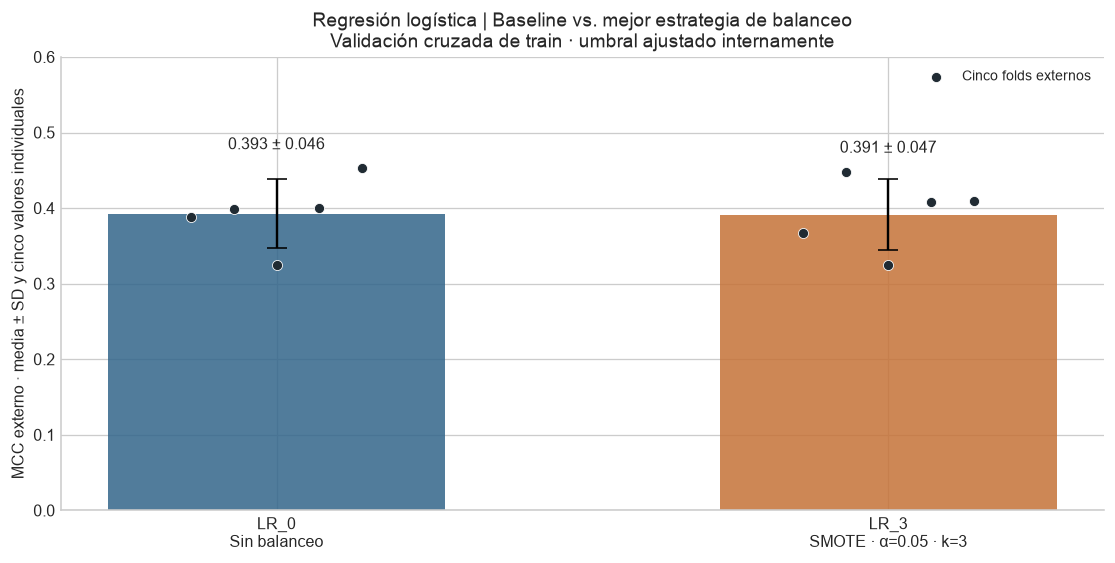

In [13]:
graficar_mcc_cv('LR')

LR_0 obtuvo MCC externo **0.3928 ± 0.0458**, frente a **0.3914 ± 0.0472** de LR_3. La diferencia balanceado menos baseline es **-0.0014**, pequeña frente a la dispersión; no demuestra superioridad estadística.

SMOTE presenta recall medio **38.5%**, frente a **37.3%** del baseline, y precision **44.4%**, frente a **46.3%**. Su kappa medio es **0.3873**, apenas por encima de **0.3865**. Los criterios pueden ordenar configuraciones cercanas de forma distinta; se mantiene la selección predefinida por MCC, SD e ID.


## 8. Umbrales seleccionados con probabilidades OOF de train

Cada una de las cinco configuraciones recibe su propio umbral final, elegido con sus probabilidades OOF de train para maximizar MCC entre 199 candidatos de 0.005 a 0.995. Ante empate numérico se prefiere el mayor umbral. El término «seleccionado» reconoce que el máximo de esta malla no garantiza el mejor desempeño en datos nuevos.

Se genera una gráfica con dos curvas: LR_0 frente a la mejor configuración balanceada seleccionada por CV externa. La tabla completa documenta los cinco umbrales. Estos valores se congelan antes de evaluar test; también se usan en las matrices de confusión y las métricas finales.

El MCC OOF de esta tabla es exploratorio porque sus etiquetas se usaron para seleccionar el umbral. La selección de modelos se basa en las cinco evaluaciones externas anteriores, con ajuste del umbral anidado, y no en este máximo exploratorio. El ajuste cambia decisiones, sin cambiar las probabilidades ni su ranking.
Para los modelos con remuestreo, las curvas usan `prob_oof_final`: predicciones de tres folds de la configuración fija elegida en la búsqueda final de train. No se mezclan con las OOF externas, que pueden provenir de distintos sampling_strategy. Las dos configuraciones sin remuestreo conservan sus OOF originales de cinco folds.


In [14]:
ids_umbral = [mid for ids in comparaciones.values() for mid in ids]
curvas_umbral = pd.DataFrame([
    {'ID': mid, 'Umbral': t, 'MCC_OOF': valor}
    for mid in ids_umbral
    for t, valor in zip(MALLA_UMBRALES, curva_mcc(y_train, prob_oof_final[mid]))
])
resumen_umbrales_train = pd.DataFrame([
    {'ID': mid, **evaluar(y_train, prob_oof_final[mid], umbrales_fijados[mid])}
    for mid in modelos
]).set_index('ID')
print('Umbrales finales seleccionados con train · MCC OOF exploratorio')
tabla(catalogo[['Modelo', 'Estrategia']].join(resumen_umbrales_train[
    ['Umbral', 'MCC', 'Kappa', 'Precision', 'Recall', 'F1']]))
umbral_train = resumen_umbrales_train.loc[ids_umbral].reset_index()

Umbrales finales seleccionados con train · MCC OOF exploratorio


,Modelo,Estrategia,Umbral,MCC,Kappa,Precision,Recall,F1
ID,,,,,,,,
LR_0,Regresión logística,Sin balanceo,0.2300,0.3983,0.3958,0.4651,0.3727,0.4138
LR_1,Regresión logística,Random Oversampling,0.2950,0.3840,0.3815,0.4496,0.3602,0.4000
LR_2,Regresión logística,Random Undersampling,0.2900,0.3757,0.3750,0.4196,0.3727,0.3947
LR_3,Regresión logística,SMOTE,0.2900,0.3878,0.3871,0.4306,0.3851,0.4066
LR_4,Regresión logística,Ponderación,0.8350,0.3154,0.3108,0.2902,0.4037,0.3377


Las configuraciones sin ponderación seleccionan umbrales entre **0.230 y 0.295**; LR_4 conserva **0.835**. LR_3 utiliza **0.290**, obtenido con las OOF de la pareja final (0.05, 3 vecinos). La ponderación cambia la escala probabilística; un umbral más alto no indica un modelo mejor.

Los valores de MCC de esta tabla sirven para ajustar el corte. La comparación de desempeño continúa basada en CV externa, y estos umbrales quedan congelados antes de test.


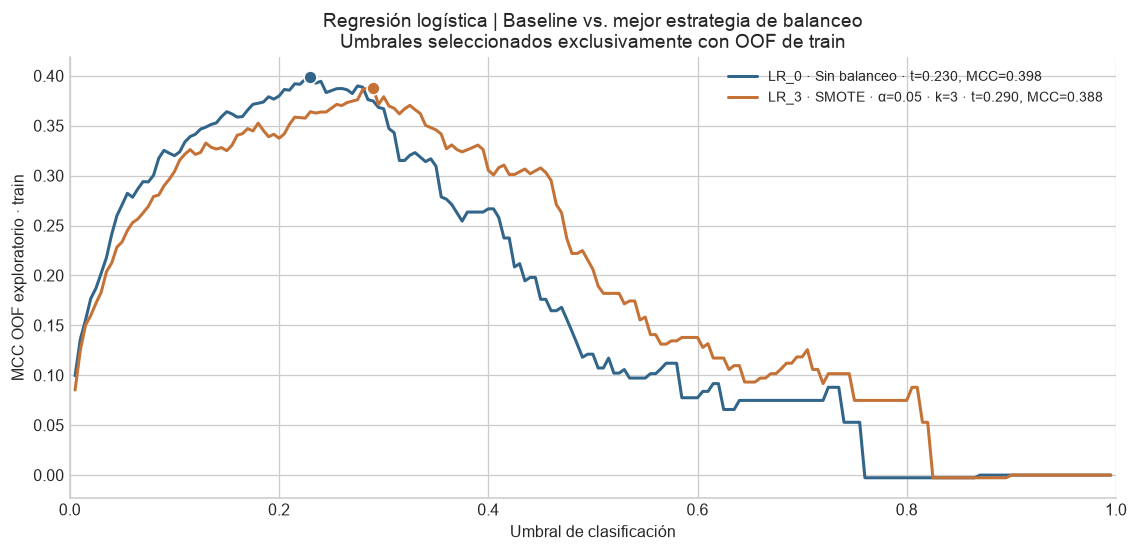

In [15]:
graficar_umbrales('LR')

LR_0 alcanza MCC OOF **0.3983** en **0.230**; LR_3, con (0.05, 3 vecinos), alcanza **0.3878** en **0.290**. En estas mismas curvas, los valores en 0.5 son **0.1211** y **0.2061**. Esa referencia describe el ajuste y no reintroduce 0.5 en la evaluación principal.

Los máximos se eligieron utilizando las etiquetas de train y pueden ser optimistas. El baseline conserva OOF de cinco folds y SMOTE reutiliza tres folds de la búsqueda final. Por ello, la comparación de generalización usa los cinco folds externos compartidos. El umbral cambia las etiquetas de decisión, sin cambiar las probabilidades ni su ranking.


## 9. Evaluación y selección de calibradores

Se comparan tres métodos de calibración: NONE (sin calibración), SIGMOID e ISOTONIC, para determinar cuál produce probabilidades de falla más confiables.

La evaluación utiliza validación cruzada de cinco folds. Dentro de cada fold, los calibradores se ajustan mediante otras cinco particiones, evitando utilizar los datos reservados para validación. Si el modelo utiliza remuestreo, este se aplica únicamente durante el entrenamiento.

El mejor método se selecciona por el menor Brier promedio en CV externa, utilizando Log Loss y después simplicidad como desempates (NONE, SIGMOID, ISOTONIC). Ambas métricas permiten evaluar la calidad de las probabilidades estimadas. ISOTONIC es más flexible, pero puede sobreajustarse cuando existen pocos casos de falla.

Log Loss complementa el análisis al penalizar especialmente las probabilidades extremas equivocadas. La regla se fija con train antes de evaluar test.

Por su parte, el Brier Score mide el error cuadrático promedio entre las probabilidades estimadas y los resultados observados. En clasificación binaria, toma valores entre 0 y 1 y ofrece una penalización acotada. Conviene utilizarlo cuando se busca evaluar la calidad global de las probabilidades predichas, sin que los errores extremos dominen tanto la métrica.

Como la calibración modifica las probabilidades, se selecciona un nuevo umbral para cada método. Sin embargo, estos umbrales no se utilizan para elegir el mejor calibrador.

Se conserva ensemble=False: el calibrador se ajusta con predicciones internas OOF y el pipeline se reentrena con todo el subentrenamiento. Los calibradores reciben la prevalencia natural. Esta comparación está condicionada a haber elegido previamente el modelo con los mismos folds externos; no evalúa de forma anidada toda la selección de modelo y calibración.

Si el pipeline recomendado utiliza SMOTE, SeleccionSamplingCV vuelve a seleccionar conjuntamente intensidad y vecinos solo con las filas recibidas por fit. Las etiquetas reservadas para calibración no participan en esa búsqueda. Con ensemble=False, el reajuste sobre train reproduce la pareja de la búsqueda final; NONE reutiliza el modelo original.


In [16]:
METODOS = ['NONE', 'SIGMOID', 'ISOTONIC']

def construir_calibrador(plantilla, metodo, mid=None):
    cv_interna = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    kwargs = dict(method=metodo.lower(), cv=cv_interna, ensemble=False, n_jobs=1)
    # Compatibilidad explícita con las dos firmas de scikit-learn.
    parametro = ('estimator' if 'estimator' in inspect.signature(CalibratedClassifierCV).parameters
                 else 'base_estimator')
    kwargs[parametro] = (SeleccionSamplingCV(plantilla=clone(plantilla), mid=(ganador_id if mid is None else mid),
                            n_splits=FOLDS_BUSQUEDA)
                         if 'sampler' in plantilla.named_steps else clone(plantilla))
    return CalibratedClassifierCV(**kwargs)

filas_cal_cv = []
prob_cal_oof = {'NONE': prob_oof_final[ganador_id].copy()}
for metodo in METODOS:
    if metodo == 'NONE':
        for fila in filas_cv:
            if fila['ID'] == ganador_id:
                filas_cal_cv.append({'Metodo': metodo, **{k:v for k,v in fila.items() if k != 'ID'}})
        continue
    p_oof = np.full(len(y_train), np.nan)
    for fold, (it, iv) in enumerate(folds, start=1):
        calibrador = construir_calibrador(modelos[ganador_id], metodo)
        calibrador.fit(X_train.iloc[it], y_train.iloc[it])
        p = probabilidad_positiva(calibrador, X_train.iloc[iv])
        p_oof[iv] = p
        filas_cal_cv.append({'Metodo': metodo, 'Fold': fold, **evaluar_probabilidades(y_train.iloc[iv], p)})
    assert np.isfinite(p_oof).all()
    prob_cal_oof[metodo] = p_oof
    print(f'{metodo}: comparación interna terminada (5 externos × 5 internos)')
calibracion_cv_folds = pd.DataFrame(filas_cal_cv)
metricas_prob = ['Brier', 'LogLoss', 'Prob_media', 'Prevalencia', 'AP', 'ROC_AUC']
calibracion_cv = calibracion_cv_folds.groupby('Metodo')[metricas_prob].mean().add_suffix('_CV')
for metrica in ['Brier', 'LogLoss']:
    calibracion_cv[metrica+'_SD'] = calibracion_cv_folds.groupby('Metodo')[metrica].std(ddof=1)
calibracion_cv['Complejidad'] = [METODOS.index(m) for m in calibracion_cv.index]
calibracion_cv = calibracion_cv.sort_values(['Brier_CV', 'LogLoss_CV', 'Complejidad'])
calibrador_elegido = calibracion_cv.index[0]
tabla(calibracion_cv[['Brier_CV', 'Brier_SD', 'LogLoss_CV', 'LogLoss_SD',
                      'Prob_media_CV', 'AP_CV', 'ROC_AUC_CV']])
umbrales_calibracion = {m: seleccionar_umbral(y_train, p) for m, p in prob_cal_oof.items()}
print('Calibrador fijado por train:', calibrador_elegido)
tabla(pd.Series(umbrales_calibracion, name='Umbral_OOF_train').to_frame())
# Se congelan las decisiones antes de entrenar y evaluar sobre test.
decisiones = {
    'ganador_MCC_CV': ganador_id, 'calibrador_train': calibrador_elegido,
    'criterio_calibracion': 'Brier promedio CV externa, desempate LogLoss y complejidad',
    'sampling_strategy_train': {mid:(None if pd.isna(v) else float(v)) for mid,v in sampling_final.items()},
    'k_neighbors_train': {mid:(None if pd.isna(k) else int(k)) for mid,k in k_neighbors_final.items()},
    'umbrales_OOF_train': deepcopy(umbrales_fijados),
    'umbrales_calibracion_OOF_train': deepcopy(umbrales_calibracion),
}
decisiones_congeladas = json.dumps(decisiones, sort_keys=True)
print(json.dumps(decisiones, indent=2, ensure_ascii=False))


SIGMOID: comparación interna terminada (5 externos × 5 internos)
ISOTONIC: comparación interna terminada (5 externos × 5 internos)


,Brier_CV,Brier_SD,LogLoss_CV,LogLoss_SD,Prob_media_CV,AP_CV,ROC_AUC_CV
Metodo,,,,,,,
NONE,0.0273,0.0022,0.1126,0.0113,0.0337,0.3367,0.8402
SIGMOID,0.0274,0.0021,0.1127,0.0106,0.0338,0.3367,0.8402
ISOTONIC,0.0275,0.0027,0.1330,0.0414,0.0337,0.2913,0.8327


Calibrador fijado por train: NONE


,Umbral_OOF_train
NONE,0.2300
SIGMOID,0.2150
ISOTONIC,0.2550


{
  "ganador_MCC_CV": "LR_0",
  "calibrador_train": "NONE",
  "criterio_calibracion": "Brier promedio CV externa, desempate LogLoss y complejidad",
  "sampling_strategy_train": {
    "LR_0": null,
    "LR_1": 0.05,
    "LR_2": 0.05,
    "LR_3": 0.05,
    "LR_4": null
  },
  "k_neighbors_train": {
    "LR_0": null,
    "LR_1": null,
    "LR_2": null,
    "LR_3": 3,
    "LR_4": null
  },
  "umbrales_OOF_train": {
    "LR_0": 0.23,
    "LR_1": 0.295,
    "LR_2": 0.29000000000000004,
    "LR_3": 0.29000000000000004,
    "LR_4": 0.8350000000000001
  },
  "umbrales_calibracion_OOF_train": {
    "NONE": 0.23,
    "SIGMOID": 0.215,
    "ISOTONIC": 0.255
  }
}


La LR recomendada es LR_0, elegida por MCC externo entre las cinco configuraciones. Se selecciona por Brier medio externo, con Log Loss y simplicidad como desempates. NONE presentó el menor Brier; NONE y Sigmoid tuvieron Log Loss casi idénticos (0.112628 y 0.112658). No aparece una mejora interna que compense añadir Sigmoid, aunque la diferencia es pequeña frente a la dispersión y no demuestra superioridad estadística.

Isotonic tuvo Log Loss 0.13298 y SD 0.04143, mayores que los de NONE. Su flexibilidad no garantizó mejor calidad probabilística con esta cantidad de eventos. Se conserva NONE como elección de train y se muestran igualmente los dos métodos ajustados para documentar su efecto; los umbrales propios de cada método no intervienen en la comparación de Brier o Log Loss.


## 10. Reentrenamiento y evaluación final en test


In [17]:
modelos_finales = {mid: clone(plantilla).fit(X_train, y_train)
                   for mid, plantilla in modelos.items()}
calibradores_finales = {'NONE': modelos_finales[ganador_id]}
for metodo in ['SIGMOID', 'ISOTONIC']:
    calibradores_finales[metodo] = construir_calibrador(modelos[ganador_id], metodo).fit(X_train, y_train)

# Primera y única llamada predict_proba sobre test por configuración final.
prob_test = {mid: probabilidad_positiva(estimador, X_test)
             for mid, estimador in modelos_finales.items()}
for estimador in modelos_finales.values():
    verificar_escalado_fit(estimador, X_train, X_test)
prob_cal_test = {'NONE': prob_test[ganador_id]}
for metodo in ['SIGMOID', 'ISOTONIC']:
    prob_cal_test[metodo] = probabilidad_positiva(calibradores_finales[metodo], X_test)

test_metricas = pd.DataFrame({mid: evaluar(y_test, p, decisiones['umbrales_OOF_train'][mid]) for mid, p in prob_test.items()}).T
resumen_test = catalogo.join(test_metricas).reindex(resumen_cv.index)
resumen_test['Sampling_train'] = pd.Series(sampling_final)
resumen_test['k_neighbors'] = pd.Series(k_neighbors_final)
print('Test con umbral propio elegido en train')
tabla(resumen_test[['Modelo', 'Estrategia', 'Sampling_train', 'k_neighbors', 'Umbral', 'Accuracy', 'MCC', 'Kappa', 'Precision',
                    'Recall', 'F1', 'ROC_AUC', 'AP', 'Pred_positivas']])
print('Test: calidad probabilística y desplazamiento de escala por balanceo')
tabla(resumen_test[['Estrategia', 'Brier', 'LogLoss', 'Prob_media', 'Prevalencia']])
dummy = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
p_dummy = probabilidad_positiva(dummy, X_test)
metricas_dummy = {**metricas_decision(y_test, dummy.predict(X_test)),
                  **evaluar_probabilidades(y_test, p_dummy)}
tabla(pd.DataFrame([metricas_dummy], index=['Siempre sin falla']))
print('Configuraciones sin predicciones positivas en test:',
      resumen_test.index[resumen_test['Pred_positivas'] == 0].tolist())
assert json.dumps(decisiones, sort_keys=True) == decisiones_congeladas


Test con umbral propio elegido en train


,Modelo,Estrategia,Sampling_train,k_neighbors,Umbral,Accuracy,MCC,Kappa,Precision,Recall,F1,ROC_AUC,AP,Pred_positivas
ID,,,,,,,,,,,,,,
LR_0,Regresión logística,Sin balanceo,N/A,N/A,0.2300,0.9667,0.4303,0.4275,0.5000,0.4000,0.4444,0.8737,0.3333,32.0000
LR_3,Regresión logística,SMOTE,0.0500,3,0.2900,0.9667,0.4303,0.4275,0.5000,0.4000,0.4444,0.8732,0.3280,32.0000
LR_2,Regresión logística,Random Undersampling,0.0500,N/A,0.2900,0.9658,0.4087,0.4052,0.4839,0.3750,0.4225,0.8767,0.3330,31.0000
LR_1,Regresión logística,Random Oversampling,0.0500,N/A,0.2950,0.9658,0.4087,0.4052,0.4839,0.3750,0.4225,0.8779,0.3321,31.0000
LR_4,Regresión logística,Ponderación,N/A,N/A,0.8350,0.9500,0.3694,0.3626,0.3276,0.4750,0.3878,0.8706,0.2577,58.0000


Test: calidad probabilística y desplazamiento de escala por balanceo


,Estrategia,Brier,LogLoss,Prob_media,Prevalencia
ID,,,,,
LR_0,Sin balanceo,0.0262,0.1044,0.0355,0.0333
LR_3,SMOTE,0.0265,0.1078,0.0475,0.0333
LR_2,Random Undersampling,0.0267,0.1076,0.0463,0.0333
LR_1,Random Oversampling,0.0268,0.1083,0.0482,0.0333
LR_4,Ponderación,0.1549,0.4795,0.3228,0.0333


,Accuracy,MCC,Kappa,Precision,Recall,F1,Pred_positivas,ROC_AUC,AP,Brier,LogLoss,Prob_media,Prevalencia
Siempre sin falla,0.9667,0.0000,0.0000,0.0000,0.0000,0.0000,0,0.5000,0.0333,0.0333,1.2015,0.0000,0.0333


Configuraciones sin predicciones positivas en test: []


LR_0 y LR_3 empatan en MCC de test (**0.4303**) y kappa (**0.4275**), con precision **50.0%** y recall **40.0%**. ROS y RUS conservan MCC **0.4087** y ponderación **0.3694**. La coincidencia de las métricas de decisión no implica igualdad de las probabilidades.

La búsqueda conjunta mejora el MCC de test de SMOTE respecto a sus cinco vecinos fijos (**0.4046 → 0.4303**). La selección del modelo permanece LR_0, fijada con CV externa; este empate en test no se utiliza para volver a elegir configuraciones.


## 11. Matrices de confusión y comparación de métricas

Se compara el baseline con el mejor tratamiento balanceado seleccionado por CV externa. Cada uno usa su propio umbral OOF de train, ya congelado.


Regresión logística · resultados finales de test
Baseline: LR_0 · Sin balanceo; mejor balanceado por CV: LR_3 · SMOTE · α=0.05 · k=3


,Baseline,Mejor balanceado,Diferencia
Métrica,,,
MCC,0.4303,0.4303,0.0000
Kappa,0.4275,0.4275,0.0000
Precision,0.5000,0.5000,0.0000
Recall,0.4000,0.4000,0.0000
F1-score,0.4444,0.4444,0.0000
Average Precision,0.3333,0.3280,-0.0052
Brier Score,0.0262,0.0265,0.0003
Log Loss,0.1044,0.1078,0.0034


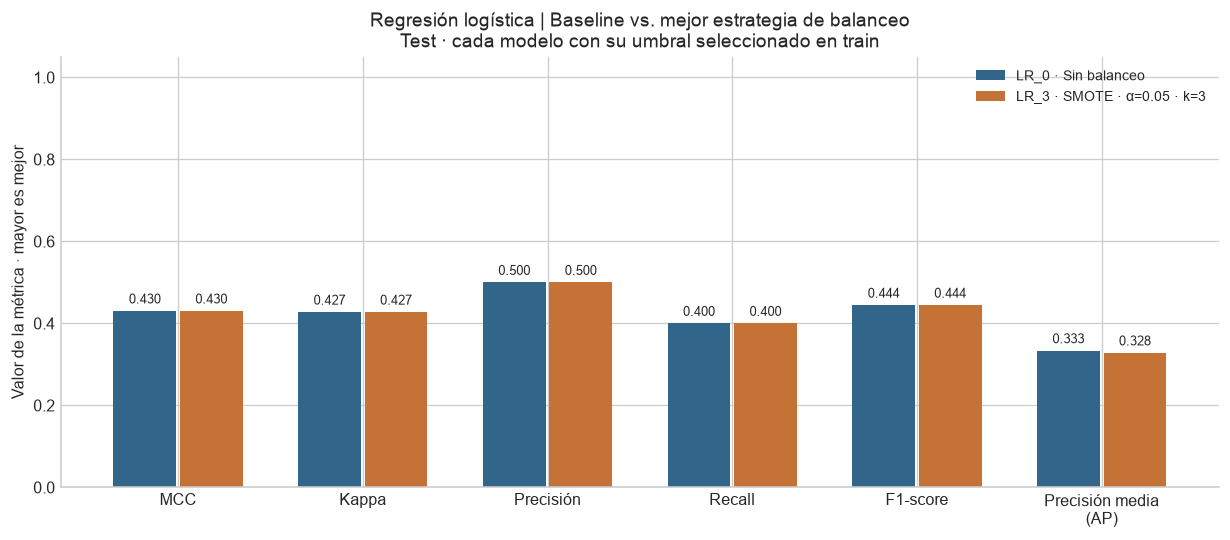

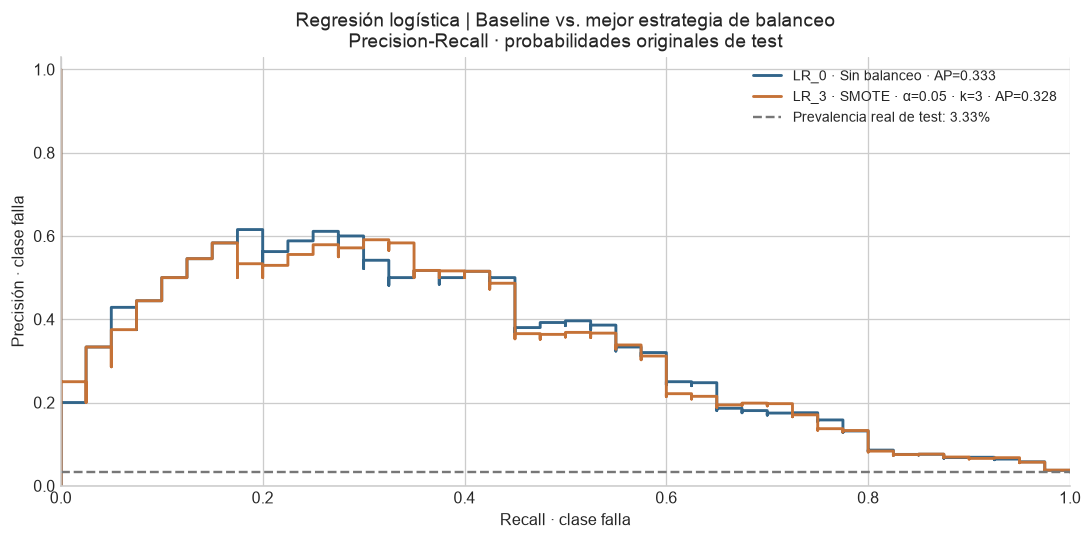

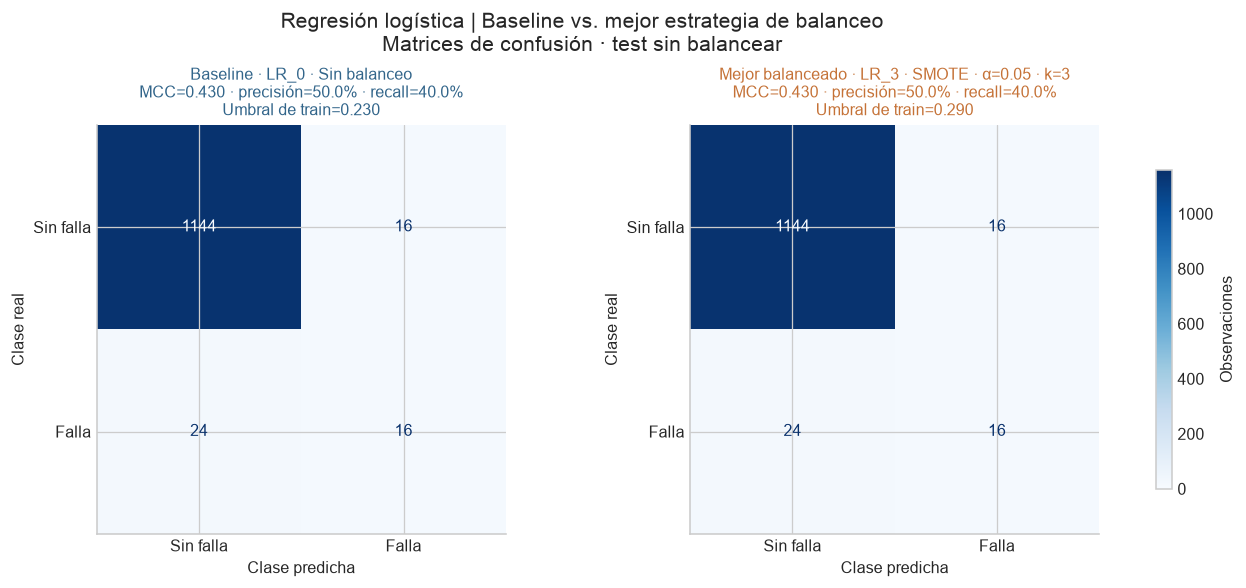

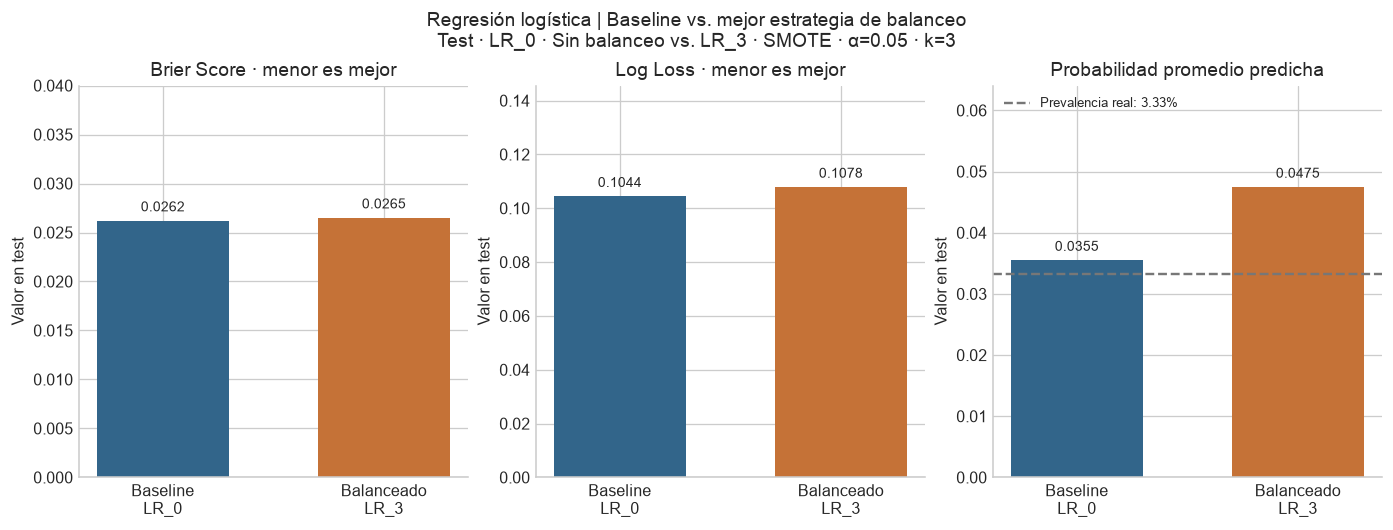

In [18]:
tablas_comparacion = {}
mostrar_bloque_test('LR')


LR_0 y LR_3 producen los mismos conteos de confusión: **16 fallas detectadas, 24 omitidas, 16 falsas alarmas y 1,144 negativos correctos**. Sus MCC, kappa, precision, recall y F1 coinciden con sus umbrales propios de train. Por tanto, el intercambio anterior de menos falsas alarmas y más omisiones con SMOTE ya no describe esta ejecución.

Las probabilidades sí difieren: AP es **0.3333** para el baseline y **0.3280** para SMOTE; Brier cambia **0.02620 → 0.02650** y Log Loss **0.10441 → 0.10785**. Igualar las métricas en un corte no garantiza igual ranking ni calidad probabilística. LR_0 mantiene su selección por CV y menores pérdidas probabilísticas en este test.


### Desempeño final de los umbrales seleccionados con train


In [19]:
# Reutilizar métricas finales y mantener separadas las tablas de umbrales por familia.
umbral_test = test_metricas.loc[ids_umbral].rename_axis('ID').reset_index()
for familia, ids in comparaciones.items():
    print(f'{NOMBRES_FAMILIA[familia]} · umbrales de train aplicados a test')
    tabla(umbral_test.loc[umbral_test['ID'].isin(ids),
        ['ID', 'Umbral', 'Accuracy', 'MCC', 'Kappa', 'Precision', 'Recall',
         'F1', 'AP', 'ROC_AUC', 'Brier', 'LogLoss']])
assert set(umbral_test['ID']) == set(ids_umbral)
for mid in modelos:
    assert test_metricas.loc[mid, 'Umbral'] == decisiones['umbrales_OOF_train'][mid]
    referencia_prob = evaluar_probabilidades(y_test, prob_test[mid])
    for metrica in ['AP', 'ROC_AUC', 'Brier', 'LogLoss']:
        assert np.isclose(test_metricas.loc[mid, metrica], referencia_prob[metrica])

Regresión logística · umbrales de train aplicados a test


,ID,Umbral,Accuracy,MCC,Kappa,Precision,Recall,F1,AP,ROC_AUC,Brier,LogLoss
0,LR_0,0.2300,0.9667,0.4303,0.4275,0.5000,0.4000,0.4444,0.3333,0.8737,0.0262,0.1044
1,LR_3,0.2900,0.9667,0.4303,0.4275,0.5000,0.4000,0.4444,0.3280,0.8732,0.0265,0.1078


Las políticas congeladas de LR_0 (umbral **0.230**) y LR_3 (umbral **0.290**) empatan en las métricas de decisión de test. Sus cortes numéricos difieren porque sus probabilidades se ajustaron con procedimientos distintos.

Se conserva LR_0 como recomendación por la regla de CV externa, sin resolver el empate de test seleccionando otra configuración. Comparar los costos de fallas omitidas y falsas alarmas sigue siendo necesario para definir una política operativa.


## 12. Calibración probabilística en test

NONE reutiliza exactamente el modelo y las probabilidades de test ya almacenadas para esa LR; SIGMOID e ISOTONIC se ajustan con train mediante CV interna y generan una sola vez sus probabilidades de test.

La tabla reporta Brier antes y después, cambio respecto a NONE, Log Loss y otras métricas. Un cambio negativo de Brier indica menor error probabilístico. Se muestran además probabilidades originales y calibradas para las mismas observaciones y su distribución por clase. La muestra ilustrativa contiene las primeras cinco observaciones de cada clase en el orden de test y no se usa para selección.

El diagrama de confiabilidad usa aproximadamente diez grupos por cuantiles y la línea ideal. Con solo 40 fallas en test, la frecuencia observada por grupo puede tener mucha incertidumbre. Brier y Log Loss evalúan calidad probabilística global y no prueban, por sí solos, calibración perfecta.


In [20]:
calibracion_test = pd.DataFrame({m: evaluar(y_test, p, decisiones['umbrales_calibracion_OOF_train'][m]) for m, p in prob_cal_test.items()}).T
calibracion_test = calibracion_test.reindex(METODOS)
calibracion_test['Elegido_en_train'] = calibracion_test.index == calibrador_elegido
columnas_cal = ['Umbral', 'Brier', 'LogLoss', 'Prob_media', 'Prevalencia', 'AP', 'ROC_AUC',
                'MCC', 'Kappa', 'Pred_positivas', 'Elegido_en_train']
tabla(calibracion_test[columnas_cal])
ref_prob = evaluar_probabilidades(y_test, np.full(len(y_test), y_train.mean()))
tabla(pd.DataFrame([ref_prob], index=['Probabilidad constante = prevalencia train'])[
    ['Brier', 'LogLoss', 'Prob_media', 'Prevalencia', 'AP', 'ROC_AUC']])
print('Se mantiene la elección de train:', calibrador_elegido)
calibracion_test['Delta_Brier_vs_NONE'] = calibracion_test['Brier'] - calibracion_test.loc['NONE', 'Brier']
print('Brier antes/después y cambio respecto a NONE')
tabla(calibracion_test[['Brier', 'Delta_Brier_vs_NONE', 'LogLoss', 'Elegido_en_train']], decimales=5)
probabilidades_test = pd.DataFrame({'Falla_real': y_test,
    **{m: prob_cal_test[m] for m in METODOS}}, index=X_test.index)
probabilidades_test.index = probabilidades_test.index.rename('Observacion')
muestra = [idx for clase in [0, 1] for idx in y_test[y_test.eq(clase)].index[:5]]
print('Mismas observaciones: probabilidades originales y calibradas')
tabla(probabilidades_test.loc[muestra], decimales=5)


,Umbral,Brier,LogLoss,Prob_media,Prevalencia,AP,ROC_AUC,MCC,Kappa,Pred_positivas,Elegido_en_train
NONE,0.2300,0.0262,0.1044,0.0355,0.0333,0.3333,0.8737,0.4303,0.4275,32.0000,True
SIGMOID,0.2150,0.0263,0.1047,0.0353,0.0333,0.3333,0.8737,0.4303,0.4275,32.0000,False
ISOTONIC,0.2550,0.0255,0.1012,0.0358,0.0333,0.3207,0.8802,0.4303,0.4275,32.0000,False


,Brier,LogLoss,Prob_media,Prevalencia,AP,ROC_AUC
Probabilidad constante = prevalencia train,0.0322,0.1461,0.0335,0.0333,0.0333,0.5000


Se mantiene la elección de train: NONE
Brier antes/después y cambio respecto a NONE


,Brier,Delta_Brier_vs_NONE,LogLoss,Elegido_en_train
NONE,0.02620,0.00000,0.10441,True
SIGMOID,0.02630,0.00010,0.10466,False
ISOTONIC,0.02547,-0.00073,0.10115,False


Mismas observaciones: probabilidades originales y calibradas


,Falla_real,NONE,SIGMOID,ISOTONIC
Observacion,,,,
2849,0,0.02429,0.02547,0.01928
2218,0,0.00991,0.01083,0.01379
1922,0,0.03923,0.04023,0.01928
3683,0,0.04688,0.04769,0.02797
715,0,0.00713,0.00791,0.00912
3512,1,0.09842,0.09683,0.09489
2903,1,0.11934,0.11645,0.09489
5918,1,0.16563,0.15951,0.14894
172,1,0.36055,0.33961,0.54118


Para LR_0, Brier fue 0.02620 con NONE, 0.02630 con Sigmoid y 0.02547 con Isotonic. Isotonic reduce el error observado en 0.00073 y Log Loss también disminuye (0.10441 -> 0.10115); Sigmoid no aporta mejora en esas dos medidas. Se conserva NONE como elección de train: escoger Isotonic por este resultado de test cambiaría el papel del conjunto reservado.

Las mismas observaciones reciben probabilidades diferentes, incluso cuando las métricas de decisión coinciden: los tres métodos tienen MCC 0.4303 y kappa 0.4275 con sus umbrales propios. La tabla ilustrativa permite ver cambios de escala, pero diez casos seleccionados por orden y clase no representan una evaluación adicional. Los errores probabilísticos se calculan con las 1,200 observaciones, y NONE reutiliza exactamente las predicciones originales.


### Curvas de calibración e incertidumbre por grupo

Se utilizan aproximadamente diez grupos por cuantiles para repartir observaciones en una muestra con pocos eventos. `calibration_curve(..., strategy="quantile")` representa la fiabilidad. Los empates, especialmente con Isotonic, pueden reducir el número efectivo de bins.

La tabla complementaria usa `qcut(..., duplicates="drop")` y muestra conteos, fallas, riesgo promedio y frecuencia observada. Los intervalos de Wilson de 95% describen incertidumbre binomial condicional a los grupos; no incorporan variación por entrenamiento, selección o dependencia entre sensores. Un grupo con cero fallas no demuestra riesgo cero, y menos de cinco fallas se marca como evidencia escasa.


In [21]:
def resumen_riesgo(verdad, p, metodo, n_bins=10):
    datos = pd.DataFrame({'y': np.asarray(verdad), 'p': np.asarray(p)})
    grupos = pd.qcut(datos['p'], q=n_bins, duplicates='drop')
    if grupos.cat.categories.size == 0:
        grupos = pd.Series(['Todos'] * len(datos))
    tabla_grupos = datos.groupby(grupos, observed=True).agg(
        N=('y', 'size'), Fallas=('y', 'sum'), Riesgo_predicho=('p', 'mean'),
        Riesgo_observado=('y', 'mean'), P_min=('p', 'min'), P_max=('p', 'max'),
    ).reset_index(drop=True)
    n = tabla_grupos['N'].to_numpy()
    r = tabla_grupos['Riesgo_observado'].to_numpy()
    z = norm.ppf(0.975)
    denominador = 1 + z*z/n
    centro = (r + z*z/(2*n)) / denominador
    semiancho = z*np.sqrt(r*(1-r)/n + z*z/(4*n*n))/denominador
    tabla_grupos['IC95_inf'] = np.maximum(0, centro-semiancho)
    tabla_grupos['IC95_sup'] = np.minimum(1, centro+semiancho)
    tabla_grupos['Evidencia_escasa'] = tabla_grupos['Fallas'] < 5
    tabla_grupos.insert(0, 'Grupo', np.arange(1, len(tabla_grupos)+1))
    tabla_grupos.insert(0, 'Metodo', metodo)
    return tabla_grupos

riesgo_test = pd.concat([resumen_riesgo(y_test, p, m) for m, p in prob_cal_test.items()], ignore_index=True)
for metodo in METODOS:
    print(f'{metodo} · evidencia por nivel de riesgo')
    tabla(riesgo_test[riesgo_test['Metodo'] == metodo])


NONE · evidencia por nivel de riesgo


,Metodo,Grupo,N,Fallas,Riesgo_predicho,Riesgo_observado,P_min,P_max,IC95_inf,IC95_sup,Evidencia_escasa
0,NONE,1,120,0,0.0008,0.0000,0.0001,0.0015,0.0000,0.0310,True
1,NONE,2,120,1,0.0024,0.0083,0.0016,0.0033,0.0015,0.0457,True
2,NONE,3,120,0,0.0044,0.0000,0.0034,0.0055,0.0000,0.0310,True
3,NONE,4,120,0,0.0070,0.0000,0.0056,0.0087,0.0000,0.0310,True
4,NONE,5,120,1,0.0103,0.0083,0.0087,0.0121,0.0015,0.0457,True
5,NONE,6,120,3,0.0146,0.0250,0.0122,0.0172,0.0085,0.0709,True
6,NONE,7,120,3,0.0208,0.0250,0.0172,0.0247,0.0085,0.0709,True
7,NONE,8,120,1,0.0317,0.0083,0.0248,0.0418,0.0015,0.0457,True
8,NONE,9,120,5,0.0593,0.0417,0.0419,0.0869,0.0179,0.0938,False
9,NONE,10,120,26,0.2037,0.2167,0.0880,0.8012,0.1524,0.2985,False


SIGMOID · evidencia por nivel de riesgo


,Metodo,Grupo,N,Fallas,Riesgo_predicho,Riesgo_observado,P_min,P_max,IC95_inf,IC95_sup,Evidencia_escasa
10,SIGMOID,1,120,0,0.0010,0.0000,0.0001,0.0018,0.0000,0.0310,True
11,SIGMOID,2,120,1,0.0027,0.0083,0.0018,0.0038,0.0015,0.0457,True
12,SIGMOID,3,120,0,0.0050,0.0000,0.0039,0.0062,0.0000,0.0310,True
13,SIGMOID,4,120,0,0.0078,0.0000,0.0062,0.0095,0.0000,0.0310,True
14,SIGMOID,5,120,1,0.0112,0.0083,0.0096,0.0131,0.0015,0.0457,True
15,SIGMOID,6,120,3,0.0157,0.0250,0.0132,0.0183,0.0085,0.0709,True
16,SIGMOID,7,120,3,0.0220,0.0250,0.0184,0.0259,0.0085,0.0709,True
17,SIGMOID,8,120,1,0.0328,0.0083,0.0260,0.0428,0.0015,0.0457,True
18,SIGMOID,9,120,5,0.0596,0.0417,0.0429,0.0859,0.0179,0.0938,False
19,SIGMOID,10,120,26,0.1950,0.2167,0.0870,0.7709,0.1524,0.2985,False


ISOTONIC · evidencia por nivel de riesgo


,Metodo,Grupo,N,Fallas,Riesgo_predicho,Riesgo_observado,P_min,P_max,IC95_inf,IC95_sup,Evidencia_escasa
20,ISOTONIC,1,370,1,0.0048,0.0027,0.0000,0.0060,0.0005,0.0151,True
21,ISOTONIC,2,135,0,0.0091,0.0000,0.0091,0.0091,0.0000,0.0277,True
22,ISOTONIC,3,164,3,0.0138,0.0183,0.0138,0.0138,0.0062,0.0524,True
23,ISOTONIC,4,307,5,0.0193,0.0163,0.0193,0.0193,0.0070,0.0376,False
24,ISOTONIC,5,105,5,0.0533,0.0476,0.0280,0.0769,0.0205,0.1067,False
25,ISOTONIC,6,119,26,0.2198,0.2185,0.0949,0.6667,0.1537,0.3009,False


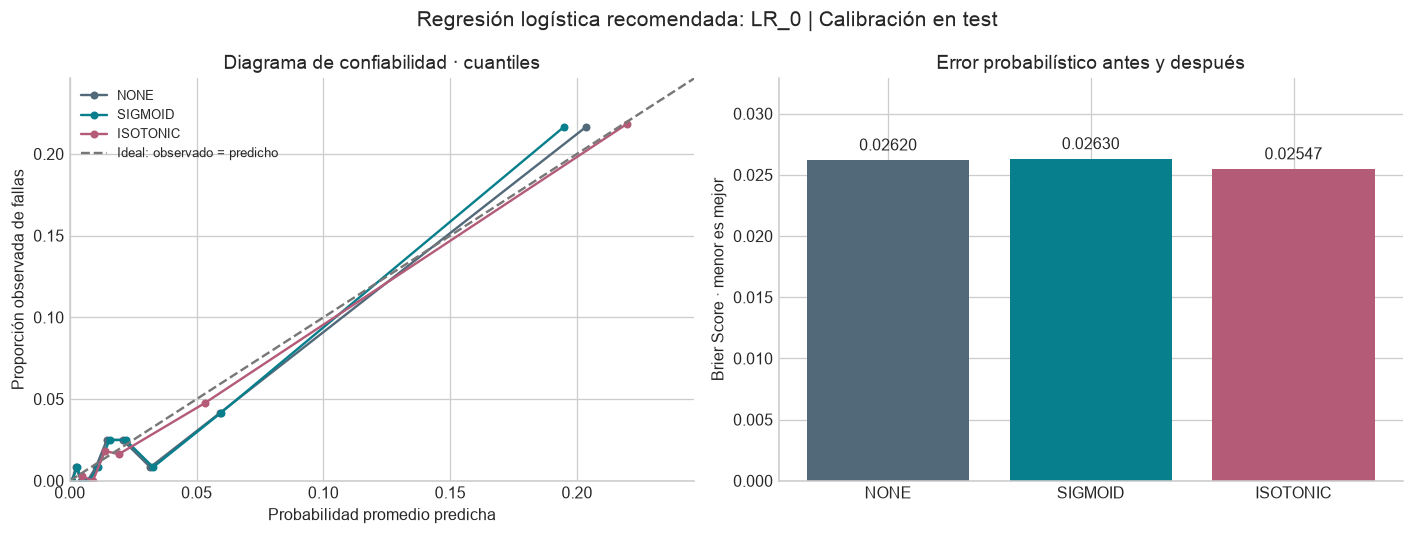

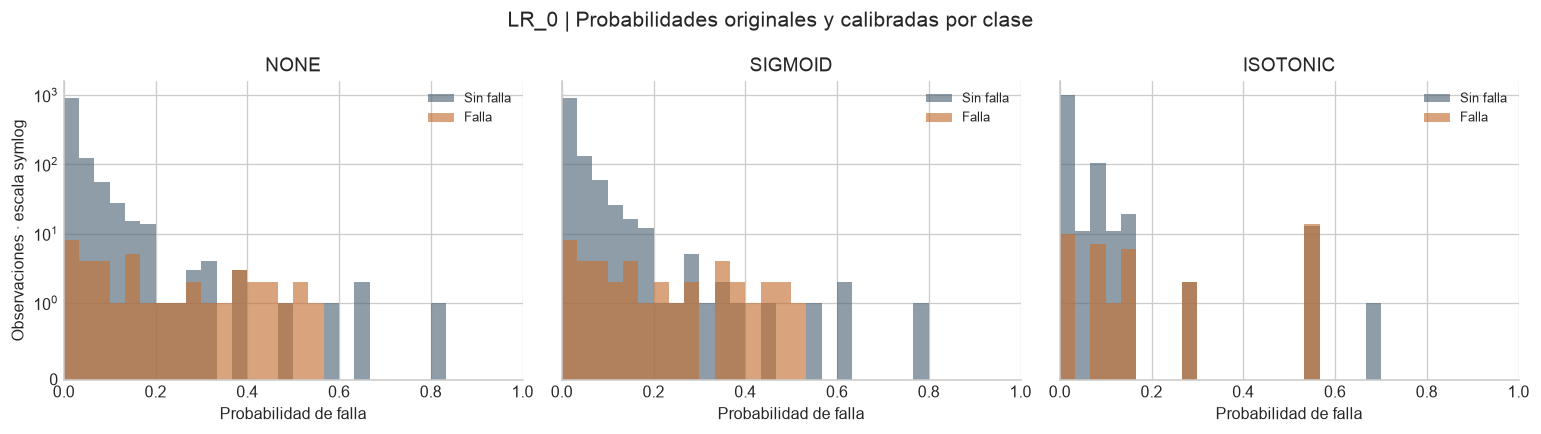

In [22]:
fig, (ax_cal, ax_brier) = plt.subplots(1, 2, figsize=(12.4, 4.7))
max_riesgo = 0.1
for metodo in METODOS:
    observada, predicha = calibration_curve(
        y_test, prob_cal_test[metodo], n_bins=10, strategy='quantile')
    ax_cal.plot(predicha, observada, marker='o', ms=4,
                    color=COLORES[metodo], label=metodo)
    max_riesgo = max(max_riesgo, float(predicha.max()), float(observada.max()))
limite = min(1.0, max_riesgo*1.12)
ax_cal.plot([0, 1], [0, 1], '--', color='#777777', label='Ideal: observado = predicho')
ax_cal.set(xlabel='Probabilidad promedio predicha', ylabel='Proporción observada de fallas',
              title='Diagrama de confiabilidad · cuantiles', xlim=(0, limite), ylim=(0, limite))
ax_cal.legend(fontsize=8)
valores_brier = calibracion_test.loc[METODOS, 'Brier'].to_numpy(dtype=float)
barras = ax_brier.bar(METODOS, valores_brier, color=[COLORES[m] for m in METODOS])
ax_brier.bar_label(barras, labels=[f'{v:.5f}' for v in valores_brier], padding=4)
ax_brier.set(ylabel='Brier Score · menor es mejor', ylim=(0, float(valores_brier.max())*1.25),
                title='Error probabilístico antes y después')
fig.suptitle(f'Regresión logística recomendada: {ganador_id} | Calibración en test', fontsize=13)
plt.tight_layout()
plt.show()

fig_hist, ejes_hist = plt.subplots(1, 3, figsize=(13.5, 3.8), sharex=True, sharey=True)
for ax_hist, metodo in zip(ejes_hist, METODOS):
    for clase, color, etiqueta in [(0, '#52697a', 'Sin falla'), (1, '#c57237', 'Falla')]:
        ax_hist.hist(prob_cal_test[metodo][np.asarray(y_test) == clase],
                        bins=np.linspace(0, 1, 31), color=color, alpha=0.65,
                        histtype='stepfilled', label=etiqueta)
    ax_hist.set_yscale('symlog', linthresh=1)
    ax_hist.set(title=metodo, xlabel='Probabilidad de falla', xlim=(0, 1))
    ax_hist.legend(fontsize=8)
ejes_hist[0].set_ylabel('Observaciones · escala symlog')
fig_hist.suptitle(f'{ganador_id} | Probabilidades originales y calibradas por clase', fontsize=13)
plt.tight_layout()
plt.show()


 En el grupo de mayor riesgo de NONE, 26 de 120 casos fallaron: 21.67% observado frente a 20.37% predicho. Isotonic aproxima su grupo superior a 21.98% predicho y 21.85% observado, pero sus 119 casos no tienen por qué coincidir exactamente con los del baseline. Esa aparente proximidad no demuestra calibración perfecta: el intervalo de NONE abarca aproximadamente 15.24%–29.85% y el de Isotonic es igualmente amplio.

Los histogramas muestran una transformación suave con Sigmoid y escalones/concentraciones con Isotonic. Las medias predichas quedan alrededor de 3.5% y no bastan para explicar la diferencia de Brier: una media cercana a prevalencia puede ocultar errores opuestos entre niveles de riesgo. Sigmoid preserva el ranking; con los empates de Isotonic, AP baja 0.3333 -> 0.3207 y ROC-AUC sube 0.8737 -> 0.8802. Es posible mejorar el error probabilístico observado sin mejorar todas las dimensiones de discriminación.

Ocho de los diez grupos de NONE y Sigmoid tienen menos de cinco fallas; Isotonic deja seis grupos efectivos, tres de ellos con evidencia escasa. El Brier menor de Isotonic es una mejora observable en este test, pero esa muestra y la comparación de train no permiten recomendarlo de manera universal. La recomendación probabilística permanece NONE.


## 13. Conclusiones finales

### Desempeño y utilidad del balanceo

El modelo de **regresión logística sin balanceo (LR_0) obtuvo la mayor media de MCC en CV externa**, con un MCC promedio de **0.3928 ± 0.0458** en validación cruzada externa y **0.4303 en test**. Entre las técnicas de balanceo, SMOTE presentó los mejores resultados, con un MCC externo de **0.3914 ± 0.0472**, con una media apenas menor que la de LR_0.

En test, SMOTE y LR_0 empatan en las métricas de decisión y los conteos de confusión: ambos detectan 16 de 40 fallas y generan 16 falsas alarmas. Sus probabilidades siguen siendo distintas y el baseline tiene menores Brier y Log Loss. La ligera ventaja media de CV no demuestra superioridad estadística.

Una posible explicación es que LR_0 conserva toda la información original y adapta la detección de fallas mediante un umbral optimizado. En cambio, las técnicas de balanceo modifican los datos: ROS repite ejemplos, RUS elimina observaciones de la clase mayoritaria y SMOTE genera casos sintéticos. Estos cambios pueden ayudar, pero también pueden afectar la capacidad del modelo para distinguir entre componentes con falla y sin falla.

### Intensidad de balanceo y umbrales de clasificación

Las tres técnicas (ROS, RUS y SMOTE) seleccionaron **`sampling_strategy=0.05`** durante la optimización final. Para SMOTE, la pareja elegida es **(0.05, k_neighbors=3)** y su umbral final es **0.290**. Esto equivale aproximadamente a un caso positivo por cada veinte negativos, es decir, **4.76% de positivos después del remuestreo**, frente al 3.35% original.

Estos resultados sugieren que **un balanceo ligero fue más conveniente que igualar ambas clases**. Aumentar demasiado los casos positivos o eliminar muchos negativos no produjo mejores resultados según MCC.

Sin embargo, `0.05` fue el mejor valor entre los candidatos evaluados, no necesariamente el mejor valor posible. Además, LR_0 conservó la mayor media externa, con una diferencia pequeña.

Por otra parte, **ajustar el umbral de clasificación permitió mejorar la detección de fallas sin necesidad de balancear los datos**. Los umbrales se seleccionaron utilizando train y se mantuvieron fijos durante la evaluación en test, evitando modificar las decisiones a partir de los resultados finales.

La búsqueda de vecinos cambió el resultado de SMOTE: su MCC externo subió **0.3839 -> 0.3914** y el de test **0.4046 -> 0.4303** respecto a mantener cinco vecinos. El óptimo final fue de tres vecinos, por lo que ampliar la búsqueda no equivale a elegir siempre un vecindario mayor. Las mejoras son observadas en este estudio; los valores en el límite de la malla no establecen un óptimo universal.

### Calibración de probabilidades y recomendación final

Se compararon tres métodos de calibración: NONE, SIGMOID e ISOTONIC, para evaluar cuál ofrecía probabilidades de falla más confiables.

La selección se realizó con base en el **menor Brier promedio en validación cruzada externa**, utilizando Log Loss y la simplicidad del método como criterios de desempate. **NONE obtuvo el mejor resultado**, por lo que no fue necesario modificar las probabilidades originales.

Aunque ISOTONIC presentó mejores valores de Brier y Log Loss en test, esto no justifica cambiar la selección realizada previamente con train.

Por lo tanto, **se recomienda utilizar LR_0, sin balanceo, sin calibración adicional (NONE) y con un umbral de clasificación de 0.230**.

Esta configuración satisface la regla de selección por MCC externo, aunque su proximidad a SMOTE impide interpretar la elección como una ventaja concluyente. Sin embargo, para una aplicación industrial real también sería importante considerar el costo de una falla no detectada frente al de una inspección innecesaria.

### Limitaciones y consideraciones finales

Los resultados deben interpretarse con precaución, ya que **se utilizaron datos sintéticos y únicamente 40 componentes con falla en test**. Además, las diferencias entre modelos fueron relativamente pequeñas frente a la variación observada entre folds, por lo que no se puede afirmar que exista una superioridad estadísticamente significativa.

La selección de los calibradores también estuvo condicionada por la elección previa del modelo, y el conjunto de test ya había sido consultado durante versiones anteriores del análisis.

En este conjunto de datos, **LR_0 y SMOTE optimizado mostraron resultados muy próximos en CV externa y empataron en las métricas de decisión de test**. Se mantiene LR_0 por la regla de selección establecida, sin que su pequeña ventaja media demuestre una mejor generalización. En las condiciones evaluadas, el remuestreo no aportó una ventaja clara frente al baseline; su utilidad debe comprobarse para cada configuración y política de decisión.

